# 05 · Scaling to images: a U-Net diffusion model on MNIST

Notebooks 01–04 developed diffusion models on 2-D toy data, where a small MLP is a good enough denoiser and
exact scores are available. Here we take the *same* objective and the *same* samplers to 784-dimensional
images. The maths does not change; the network and the engineering around it do. This notebook is about those
practical details: the architecture, the training recipe, the samplers on images, and how to tell whether the samples are any good.

**You will learn:**
- why an MLP is a poor denoiser for images, and which inductive biases a **U-Net** builds in;
- to build the U-Net's parts yourself: residual blocks with **FiLM** time conditioning, **GroupNorm**,
  **self-attention**, down/up-sampling, **zero-initialised** output layers;
- the training recipe used in practice: data scaling, AdamW with warm-up, gradient clipping, **EMA** weights,
  bfloat16 mixed precision, checkpointing;
- DDPM vs DDIM on images, **x0-clipping**, and why sampling is **coarse-to-fine** ("spectral autoregression");
- how to evaluate samples: nearest neighbours (memorisation), class coverage, and **Fréchet distances / FID**
  with their pitfalls.

**Prerequisites:** 01 (forward process, schedules), 02 (DDPM loss and ancestral sampling),
03 (scores, Tweedie's formula), 04 (DDIM).

**Runtime:** CPU ≈ 15–20 min on an otherwise idle 4-core machine, more than half of it the in-notebook training run
(bfloat16 autocast; much slower on a busy machine). CUDA GPU ≈ 5 min with the GPU default of 4 000 training
steps, plus ≈ 10 min once if `dmtools` has to train the reference checkpoint (section 4).

In [1]:
import contextlib
import copy
import math
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import linalg

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
                     "axes.labelsize": 9, "legend.fontsize": 8,
                     "image.interpolation": "nearest"})   # show pixels as pixels (and keep the notebook small)

# bfloat16 mixed precision: ~2x faster on CUDA GPUs and on recent x86 CPUs (AVX-512/AMX).
# Off on Apple MPS. If it turns out *slower* on your CPU, set USE_AMP = False.
USE_AMP = device.type == "cpu" or (device.type == "cuda" and torch.cuda.is_bf16_supported())


def autocast():
    """Mixed-precision context for forward passes (a no-op when USE_AMP is False)."""
    if not USE_AMP:
        return contextlib.nullcontext()
    return torch.autocast(device.type, dtype=torch.bfloat16)


GPU = device.type == "cuda"
# In-notebook training run. On a GPU, ~20_000 steps gives clean digits (~10 min); the default stays below the
# reference model's training length so that "the longer-trained reference" of section 4 really is longer-trained.
TRAIN_STEPS = 20 if FAST else (4000 if GPU else 1500)
BATCH, LR, WARMUP = 64, 2e-4, (5 if FAST else 200)
N_EVAL = 32 if FAST else (2000 if GPU else 512)   # DDIM-50 samples per model for the evaluation
N_DDPM = 8 if FAST else (512 if GPU else 128)     # DDPM-1000 samples (1000 network calls each!)
C_REAL, C_DDPM, C_DDIM, C_MINE = "0.35", "tab:blue", "tab:green", "tab:orange"  # colours used throughout
print(f"FAST={FAST}  USE_AMP={USE_AMP}  TRAIN_STEPS={TRAIN_STEPS}  N_EVAL={N_EVAL}  N_DDPM={N_DDPM}")

Using device: cpu
FAST=False  USE_AMP=True  TRAIN_STEPS=1500  N_EVAL=512  N_DDPM=128


## 1 · From 2-D to 784-D: what does an image denoiser need?

Nothing in the *maths* of notebooks 01–04 depends on the dimension. An MNIST digit is a vector
$x_0\in\mathbb{R}^{1\times 28\times 28}\cong\mathbb{R}^{784}$, the forward process is the same, and so is the loss

$$\mathcal{L}(\theta)=\mathbb{E}_{t,\,x_0,\,\epsilon}\Big\|\epsilon-\epsilon_\theta\big(\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\;t\big)\Big\|^2 .$$

What changes is *what the network has to represent*. By Tweedie's formula (notebook 03), predicting the noise is
the same as predicting the posterior mean of the clean image,

$$\hat x_0(x_t,t)=\mathbb{E}[x_0\mid x_t]=\frac{x_t-\sqrt{1-\bar\alpha_t}\;\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},$$

so the ideal $\epsilon_\theta$ is a Bayes-optimal **denoiser for images at every noise level**, a map
$\mathbb{R}^{784}\to\mathbb{R}^{784}$. Images have structure that a generic MLP would have to learn from scratch:

1. **Locality and translation equivariance.** A stroke is a stroke wherever it appears. If the data distribution
   is (roughly) shift-invariant, so is the posterior, and the optimal denoiser is shift-*equivariant*: denoising a
   shifted image gives the shifted denoised image. A convolution has this built in through weight sharing, using a
   handful of parameters. A dense layer has $784^2$ independent weights and must learn the same stroke detector
   separately at every position.
2. **Multi-scale structure.** At high noise only coarse structure survives (which digit, roughly where), and the
   optimal denoiser has to average over large regions. At low noise it must restore fine local detail. Down-sampling
   gives large receptive fields cheaply; skip connections carry the fine detail around the bottleneck. That is
   the **U-Net** (Ronneberger et al. 2015).
3. **Global context.** Whether a blob in the top-left is the top of a 7 or of a 9 depends on the whole image.
   **Self-attention** lets every position look at every other position. Its cost grows like $(HW)^2$: 256 times
   more at 28×28 than at 7×7. Image diffusion models therefore use attention only on down-sampled feature maps
   (typically 32×32 or smaller) or on patch / latent tokens.

Let's check claim 1 numerically: a convolution commutes with shifts and a dense layer does not.

In [2]:
x_train, y_train = dm.load_mnist(train=True)
x_test, y_test = dm.load_mnist(train=False)
print(f"train {tuple(x_train.shape)}, test {tuple(x_test.shape)}")


def shift_right(img, k):
    """Circularly shift a batch of images (B, C, H, W) by k pixels to the right."""
    return torch.roll(img, shifts=k, dims=-1)


torch.manual_seed(0)
conv = nn.Conv2d(1, 1, 3, padding=1, padding_mode="circular")  # circular padding -> exact equivariance
dense = nn.Linear(784, 784)


def apply_dense(z):
    return dense(z.flatten(1)).view_as(z)


img = x_test[:8]
with torch.no_grad():
    for name, layer, module in [("3x3 conv", conv, conv), ("dense layer", apply_dense, dense)]:
        err = (layer(shift_right(img, 3)) - shift_right(layer(img), 3)).abs().max().item()
        scale = layer(img).abs().max().item()
        print(f"{name:12s} params {dm.count_params(module):>8,d} | "
              f"max |f(shift x) - shift f(x)| = {err:.1e}   (output scale {scale:.2f})")

train (60000, 1, 28, 28), test (10000, 1, 28, 28)
3x3 conv     params       10 | max |f(shift x) - shift f(x)| = 0.0e+00   (output scale 0.82)
dense layer  params  615,440 | max |f(shift x) - shift f(x)| = 2.9e+00   (output scale 2.39)


The convolution is exactly shift-equivariant (up to float rounding) with 10 parameters. The dense layer is not,
even with 600k parameters. The real U-Net is only *approximately* equivariant: it uses zero padding (borders
break the symmetry) and stride-2 down-sampling, which is equivariant only to shifts by multiples of the total
stride (4 pixels here).
Inductive biases are soft constraints, which is usually what you want.

## 2 · Building the U-Net, one component at a time

This is the architecture we will build (the configuration `dm.MNIST_RECIPE`, about 1.2M parameters):

```
 x_t (1×28×28)                                                              ε̂ (1×28×28)
   └► conv ─► [Res] ──────────────────────────────────────────────► [Res][Res] ─► GN·SiLU·conv ─┘
 28×28, 32 ch  │ stride-2 conv                         nearest-up+conv ▲
 14×14, 64 ch  └► [Res] ───────────────────────────────────► [Res][Res]
                    │ stride-2 conv            nearest-up+conv ▲
 7×7,  64 ch        └► [Res+Attn] ─► middle: Res·Attn·Res ─► [Res+Attn][Res+Attn]

 t ─► sinusoidal features ─► MLP ─► e_t  ──(FiLM: injected into every Res block)
```

Every encoder output is pushed on a stack and **concatenated** into the decoder at the same resolution (the
horizontal arrows; there are 6 such skips). We now write each piece ourselves and check it against the version in
`dmtools`.

### 2.1 Residual block with FiLM time conditioning, and GroupNorm

One network has to denoise at all 1000 noise levels. The right operation at $t=999$ (heavy smoothing,
guessing the global shape) is very different from the one at $t=0$ (almost the identity). So the time
embedding $e_t=\mathrm{MLP}(\text{sinusoidal}(t))$ is allowed to **rescale and shift every channel** of every
residual block. This is FiLM, feature-wise linear modulation (Perez et al. 2018):

$$h=\mathrm{Conv}_1\big(\mathrm{SiLU}(\mathrm{GN}(x))\big),\qquad (\gamma_t,\beta_t)=W\,\mathrm{SiLU}(e_t)+b\;\in\mathbb{R}^{C}\times\mathbb{R}^{C},$$
$$h\leftarrow\mathrm{GN}(h)\odot(1+\gamma_t)+\beta_t,\qquad
  \mathrm{out}=\mathrm{skip}(x)+\mathrm{Conv}_2\big(\mathrm{SiLU}(h)\big).$$

Implementation details that matter:
* **FiLM after normalisation.** GroupNorm removes each channel's scale and offset; FiLM then sets new,
  $t$-dependent ones. Writing $(1+\gamma)$ instead of $\gamma$ means "no modulation" corresponds to $\gamma=0$.
* **Zero-initialised last conv.** With $\mathrm{Conv}_2=0$ at initialisation, each block starts as its skip path,
  so the deep network starts out as a shallow, well-conditioned function and the residual branches switch on
  during training. The U-Net's final output conv is zero-initialised too (section 2.4).
* **GroupNorm, not BatchNorm.** In a diffusion minibatch every sample has a *different* noise level.
  BatchNorm would normalise a clean-ish image with statistics pooled from pure-noise images, make each output
  depend on the other samples in the batch, and behave differently at sampling time, when the whole batch shares one
  $t$. GroupNorm (Wu & He 2018) normalises each sample on its own, over groups of channels.

In [3]:
def num_groups(ch):
    """GroupNorm groups: the largest of 32, 16, ..., 2 that leaves >= 4 channels per group (else 1)."""
    return next((g for g in (32, 16, 8, 4, 2) if ch % g == 0 and ch // g >= 4), 1)


class MyResBlock(nn.Module):
    """GN -> SiLU -> conv -> GN -> FiLM(e_t) -> SiLU -> conv, plus a (1x1-conv) skip path."""

    def __init__(self, in_ch, out_ch, emb_dim, dropout=0.0):
        super().__init__()
        self.norm1 = nn.GroupNorm(num_groups(in_ch), in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb = nn.Linear(emb_dim, 2 * out_ch)            # e_t -> per-channel (scale, shift)
        self.norm2 = nn.GroupNorm(num_groups(out_ch), out_ch)
        self.drop = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        nn.init.zeros_(self.conv2.weight)                    # residual branch starts at exactly 0
        nn.init.zeros_(self.conv2.bias)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        # (B, 2*out_ch) -> (B, 2*out_ch, 1, 1): broadcast the same scale/shift over all pixels of a channel
        scale, shift = self.emb(F.silu(emb))[:, :, None, None].chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale) + shift              # FiLM
        h = self.conv2(self.drop(F.silu(h)))
        return h + self.skip(x)


torch.manual_seed(0)
emb_dim = 128
time_mlp = nn.Sequential(dm.SinusoidalEmbedding(32), nn.Linear(32, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
block = MyResBlock(32, 64, emb_dim)
h_in = torch.randn(4, 32, 14, 14)
e_t = time_mlp(torch.tensor([0, 250, 500, 999]))

with torch.no_grad():
    print("at init, block(x) == skip(x) exactly:", torch.equal(block(h_in, e_t), block.skip(h_in)))
    nn.init.normal_(block.conv2.weight, std=0.05)          # pretend training switched the branch on
    ref_block = dm.ResBlock(32, 64, emb_dim)
    ref_block.load_state_dict(block.state_dict())           # same parameter names -> same function
    print(f"max |MyResBlock - dm.ResBlock| = {(block(h_in, e_t) - ref_block(h_in, e_t)).abs().max():.1e}")
    # FiLM at work: the same input gives different outputs at different t
    same_x = h_in[:1].expand(4, -1, -1, -1)
    out_t = block(same_x, e_t)
    rel = [((out_t[i] - out_t[0]).norm() / out_t[0].norm()).item() for i in range(1, 4)]
    print("same input: relative change of the output vs t=0, for t = 250/500/999:", [f"{r:.1%}" for r in rel])

    # GroupNorm vs BatchNorm: does sample 0's output depend on the *other* samples in the batch?
    gn, bn = nn.GroupNorm(8, 32), nn.BatchNorm2d(32)        # bn in training mode = batch statistics
    batch_a = torch.randn(8, 32, 7, 7)
    batch_b = batch_a.clone()
    batch_b[1:] = 5 * torch.randn(7, 32, 7, 7)               # same sample 0, very different batch-mates
    for name, norm in [("GroupNorm", gn), ("BatchNorm", bn)]:
        d = (norm(batch_a)[0] - norm(batch_b)[0]).abs().max().item()
        print(f"{name:9s}: change in sample 0's output when the rest of the batch changes = {d:.2e}")

at init, block(x) == skip(x) exactly: True
max |MyResBlock - dm.ResBlock| = 0.0e+00
same input: relative change of the output vs t=0, for t = 250/500/999: ['5.4%', '5.6%', '4.1%']
GroupNorm: change in sample 0's output when the rest of the batch changes = 0.00e+00
BatchNorm: change in sample 0's output when the rest of the batch changes = 2.75e+00


All three checks pass. The fresh block is exactly its skip path. Our block and `dm.ResBlock` compute the same
function. FiLM makes the same input produce different outputs at different $t$ (only mildly at random
initialisation, since the embedding weights are small; training decides how strongly to modulate). And GroupNorm, unlike
BatchNorm, treats every sample independently. We will rely on that last property in section 6, where we
evaluate many copies of one image in a single batch.

### 2.2 Self-attention at low resolution

Treat the $N=HW$ positions of a feature map as tokens $h_i\in\mathbb{R}^C$. With per-head queries, keys and values
$q_i=W_qh_i,\;k_i=W_kh_i,\;v_i=W_vh_i\in\mathbb{R}^d$:

$$a_{ij}=\frac{\exp(q_i^\top k_j/\sqrt d)}{\sum_{j'}\exp(q_i^\top k_{j'}/\sqrt d)},\qquad
  \mathrm{out}_i=h_i+W_o\sum_j a_{ij}\,v_j .$$

Each output position mixes information from **all** positions, with weights that depend on the content. This
gives a global receptive field in a single layer. The cost is the $N\times N$ matrix $a$ per head and image.
$W_o$ is zero-initialised, so the block also starts as the identity.

In [4]:
class MyAttnBlock(nn.Module):
    """Multi-head self-attention over the H*W positions of a feature map, with a residual connection."""

    def __init__(self, ch, heads=4):
        super().__init__()
        self.heads = heads
        self.norm = nn.GroupNorm(num_groups(ch), ch)
        self.qkv = nn.Conv2d(ch, 3 * ch, 1)      # a 1x1 conv = the same linear map at every position
        self.proj = nn.Conv2d(ch, ch, 1)         # W_o
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x, emb=None):
        B, C, H, W = x.shape
        d = C // self.heads
        q, k, v = self.qkv(self.norm(x)).reshape(B, 3, self.heads, d, H * W).unbind(1)  # each (B, heads, d, N)
        attn = (q.transpose(-1, -2) @ k / math.sqrt(d)).softmax(dim=-1)  # (B, heads, N, N), rows sum to 1
        out = attn @ v.transpose(-1, -2)                                  # (B, heads, N, d)
        return x + self.proj(out.transpose(-1, -2).reshape(B, C, H, W))


torch.manual_seed(0)
attn_block = MyAttnBlock(64)
nn.init.normal_(attn_block.proj.weight, std=0.1)   # un-zero W_o so that the comparison is not trivial
ref_attn = dm.AttnBlock(64)                         # uses the fused F.scaled_dot_product_attention
ref_attn.load_state_dict(attn_block.state_dict())
feat = torch.randn(2, 64, 7, 7, requires_grad=True)
out = attn_block(feat)
print(f"max |MyAttnBlock - dm.AttnBlock| = {(out - ref_attn(feat)).abs().max():.1e}")

# Receptive field of ONE layer: how much of the output at the centre (3, 3) comes from far-away positions?
for name, layer in [("3x3 conv", nn.Conv2d(64, 64, 3, padding=1)), ("attention", attn_block)]:
    g, = torch.autograd.grad(layer(feat)[0, :, 3, 3].sum(), feat)
    influence = g[0].abs().sum(0)                       # (7, 7): sensitivity to each input position
    outside = 1 - (influence[2:5, 2:5].sum() / influence.sum()).item()
    print(f"{name:9s}: {(influence > 0).sum().item():2d} of 49 input positions influence output (3,3); "
          f"{outside:4.0%} of the influence comes from outside its 3x3 neighbourhood")

for hw in (28, 14, 7):
    print(f"attention matrix at {hw:2d}x{hw:<2d}: {(hw * hw) ** 2:>7,d} entries per head and image")

max |MyAttnBlock - dm.AttnBlock| = 0.0e+00
3x3 conv :  9 of 49 input positions influence output (3,3);   0% of the influence comes from outside its 3x3 neighbourhood
attention: 49 of 49 input positions influence output (3,3);  20% of the influence comes from outside its 3x3 neighbourhood
attention matrix at 28x28: 614,656 entries per head and image
attention matrix at 14x14:  38,416 entries per head and image
attention matrix at  7x7 :   2,401 entries per head and image


Our explicit softmax attention agrees with PyTorch's fused kernel. A 3×3 conv sees 9 positions. One attention
layer draws a substantial part of its output from the whole 7×7 map. (Strictly, GroupNorm alone already couples
all positions a little, through the shared mean and variance, which is why we measure influence *mass*.) The cost
is why this small model uses attention only at the lowest resolution: the attention matrix at 28×28 is 256 times
larger than at 7×7. (784 tokens would still be affordable on a GPU; the 256-fold cost just buys little at this
size.) Large image models (Stable Diffusion, DiT) use attention more widely, but on down-sampled feature maps or
patch tokens, for the same reason.

### 2.3 Down- and up-sampling

* **Down:** a 3×3 convolution with stride 2. It is learned, and cheaper than conv + pooling.
* **Up:** nearest-neighbour up-sampling followed by a 3×3 convolution. Transposed convolutions tend to produce
  checkerboard artefacts.
* **Gotcha:** every down-sampling halves $H$ and $W$, and the decoder must land on exactly the encoder's sizes
  for the skip concatenations. The image size must therefore be divisible by $2^{\text{levels}-1}$: 28 → 14 → 7
  works for 3 levels, and 30 → 15 → 8 does not (8 up-samples to 16 ≠ 15). Neither would a 4th level for 28
  (7 → 4 → 8 ≠ 7).

In [5]:
down = nn.Conv2d(32, 32, 3, stride=2, padding=1)
up = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(32, 32, 3, padding=1))
with torch.no_grad():
    for size in (28, 30):
        h = torch.randn(1, 32, size, size)
        hs = [h]
        for _ in range(2):
            hs.append(down(hs[-1]))
        back = up(up(hs[-1]))
        sizes = " -> ".join(str(z.shape[-1]) for z in hs) + " -> up -> " + str(up(hs[-1]).shape[-1]) + \
            " -> up -> " + str(back.shape[-1])
        ok = all(up(hs[i + 1]).shape == hs[i].shape for i in range(2))
        print(f"{size}x{size}: {sizes}   decoder matches encoder at every level: {ok}")

28x28: 28 -> 14 -> 7 -> up -> 14 -> up -> 28   decoder matches encoder at every level: True
30x30: 30 -> 15 -> 8 -> up -> 16 -> up -> 32   decoder matches encoder at every level: False


### 2.4 The assembled U-Net

`dm.UNet` is these pieces assembled: its `ResBlock` and `AttnBlock` are exactly the classes we just checked
against our own. It adds the time-embedding MLP, an input conv, the stack of skip connections, and a
**zero-initialised output conv**. Rather than treat it as a black box, we re-run its forward pass step by step
and print every tensor shape. Then we check that our step-by-step pass reproduces `model(x, t)`.

In [6]:
unet = dm.UNet(**dm.MNIST_RECIPE)
print("recipe:", dm.MNIST_RECIPE)
print(f"total parameters: {dm.count_params(unet):,}")
for part in ["time_emb", "inp", "down", "mid", "up", "out"]:
    print(f"   {part:9s}{dm.count_params(getattr(unet, part)):>9,d}")


def describe(blocks):
    """Short name of a list of layers, e.g. 'ResBlock+AttnBlock+Upsample+Conv'."""
    names = []
    for b in blocks:
        name = type(b).__name__.replace("Conv2d", "Conv")
        if isinstance(b, nn.Conv2d) and b.stride == (2, 2):
            name = "Conv(stride 2)"
        names.append(name)
    return "+".join(names)


def trace_unet(model, x, t):
    """Re-run dm.UNet.forward step by step, printing shapes and the skip stack. Returns the output."""
    emb = model.time_emb(t)                       # (B, 4*base_ch): sinusoidal features -> MLP
    print(f"{'input x':56s}{tuple(x.shape)}\n{'time embedding e_t':56s}{tuple(emb.shape)}")
    h = model.inp(x)
    skips = [h]
    print(f"{'inp conv':56s}{tuple(h.shape)}  -> push skip 0")
    for blocks in model.down:
        h = model._run(blocks, h, emb)
        skips.append(h)
        print(f"{'down  ' + describe(blocks):56s}{tuple(h.shape)}  -> push skip {len(skips) - 1}")
    h = model._run(model.mid, h, emb)
    print(f"{'mid   ' + describe(model.mid):56s}{tuple(h.shape)}")
    for blocks in model.up:
        k = len(skips) - 1
        h = torch.cat([h, skips.pop()], dim=1)    # concatenate along channels
        h = model._run(blocks, h, emb)
        print(f"{f'up    cat skip {k} -> ' + describe(blocks):56s}{tuple(h.shape)}")
    out = model.out(h)
    print(f"{'out   GroupNorm+SiLU+Conv':56s}{tuple(out.shape)}")
    return out


x_dummy, t_dummy = torch.randn(2, 1, 28, 28), torch.tensor([10, 900])
with torch.no_grad():
    print("fresh U-Net output is exactly zero:", bool((unet(x_dummy, t_dummy) == 0).all()), "\n")
    check_net = copy.deepcopy(unet)
    for p in check_net.parameters():              # un-zero the zero-initialised layers for a real test
        if not p.any():
            p.normal_(0, 0.02)
    traced = trace_unet(check_net, x_dummy, t_dummy)
    print(f"\nmax |trace - model(x, t)| = {(traced - check_net(x_dummy, t_dummy)).abs().max():.1e}")

# Which parameters receive a gradient on the very first training step of the fresh (zero-output) U-Net?
F.mse_loss(unet(x_dummy, t_dummy), torch.randn_like(x_dummy)).backward()
moving = [name for name, p in unet.named_parameters() if p.grad is not None and p.grad.abs().max() > 0]
print(f"parameters with a non-zero gradient at step 1: {moving}  ({len(moving)} of {len(list(unet.parameters()))})")
unet.zero_grad(set_to_none=True)

recipe: {'base_ch': 32, 'ch_mults': (1, 2, 2), 'n_res': 1, 'attn_levels': (2,), 'dropout': 0.0}
total parameters: 1,191,233
   time_emb    20,736
   inp            320
   down       254,688
   mid        198,016
   up         717,120
   out            353
fresh U-Net output is exactly zero: True 

input x                                                 (2, 1, 28, 28)
time embedding e_t                                      (2, 128)
inp conv                                                (2, 32, 28, 28)  -> push skip 0
down  ResBlock                                          (2, 32, 28, 28)  -> push skip 1
down  Conv(stride 2)                                    (2, 32, 14, 14)  -> push skip 2
down  ResBlock                                          (2, 64, 14, 14)  -> push skip 3
down  Conv(stride 2)                                    (2, 64, 7, 7)  -> push skip 4
down  ResBlock+AttnBlock                                (2, 64, 7, 7)  -> push skip 5
mid   ResBlock+AttnBlock+ResBlock        

parameters with a non-zero gradient at step 1: ['out.2.weight', 'out.2.bias']  (2 of 166)


Reading the trace: the encoder goes 28 → 14 → 7 while channels go 32 → 64. The decoder pops the skips in reverse
order, so every concatenation pairs features of the same resolution. Attention runs only on the 7×7 maps.

A fresh U-Net outputs **exactly zero**, so it initially predicts $\hat\epsilon=0$ and the initial loss is
$\mathbb{E}\|\epsilon\|^2/784 = 1$. This does not stop learning, but it changes *how* learning starts, as the
last printout shows. On the first step only the output conv receives a gradient: its weight gradient is
(activations × error), which is non-zero, but the error it passes back to the rest of the network is multiplied by
its zero weights. Once the output conv has moved, gradients flow backwards, and the zero-initialised residual
branches switch on over the next steps. A zero output delays the interior by a step or two; it does not block it.
We will see the loss start at 1 in section 4.

## 3 · Data: MNIST in $[-1, 1]$

`dm.load_mnist` returns images scaled to $[-1,1]$ (background $=-1$, ink $=+1$). Why this matters:

* **The noise schedule assumes data of unit scale.** The forward process ends at
  $x_{T-1}=\sqrt{\bar\alpha_{T-1}}\,x_0+\sqrt{1-\bar\alpha_{T-1}}\,\epsilon$, and the sampler *starts* from
  $\mathcal{N}(0,I)$. That is only consistent if $\sqrt{\bar\alpha_{T-1}}\,x_0$ is negligible, which holds when
  $x_0=O(1)$. The signal-to-noise ratio is $\mathrm{SNR}(t)=\bar\alpha_t\,\mathrm{Var}[x_0]/(1-\bar\alpha_t)$,
  so rescaling the data shifts *which* timesteps carry information.
* **A known, bounded range** lets us clip $\hat x_0$ to $[-1,1]$ during sampling (section 5).

"Centred" here means centred *range*. The mean pixel is not 0: most pixels are background. What matters is that the
scale is $O(1)$ and the support is symmetric and known.

In [7]:
schedule = dm.NoiseSchedule(T=1000, kind="linear", device=device)
abar = schedule.alpha_bars.cpu().double()
print(f"pixels in [{x_train.min():.0f}, {x_train.max():.0f}], mean {x_train.mean():.3f}, std {x_train.std():.3f}\n")

x01 = (x_train[:10_000].double() + 1) / 2   # the same images in [0, 1]
print(f"{'scaling':>9s} | {'pixel std':>9s} | {'SNR(t) drops below 1 at':>23s} | "
      f"{'max signal left in x_T-1':>24s}")
scalings = {"[-1, 1]": 2 * x01 - 1, "[0, 1]": x01, "[0, 255]": 255 * x01}
for name, x in scalings.items():
    snr = abar * x.var() / (1 - abar)
    below = torch.nonzero(snr < 1)
    t_cross = f"t = {below[0].item()}" if len(below) else "never"
    left = (abar[-1].sqrt() * x).abs().amax(dim=(1, 2, 3)).mean().item()
    print(f"{name:>9s} | {x.std().item():9.3f} | {t_cross:>23s} | {left:24.3f}")

pixels in [-1, 1], mean -0.739, std 0.616

  scaling | pixel std | SNR(t) drops below 1 at | max signal left in x_T-1


  [-1, 1] |     0.617 |                 t = 175 |                    0.006
   [0, 1] |     0.309 |                  t = 91 |                    0.006


 [0, 255] |    78.718 |                 t = 928 |                    1.619


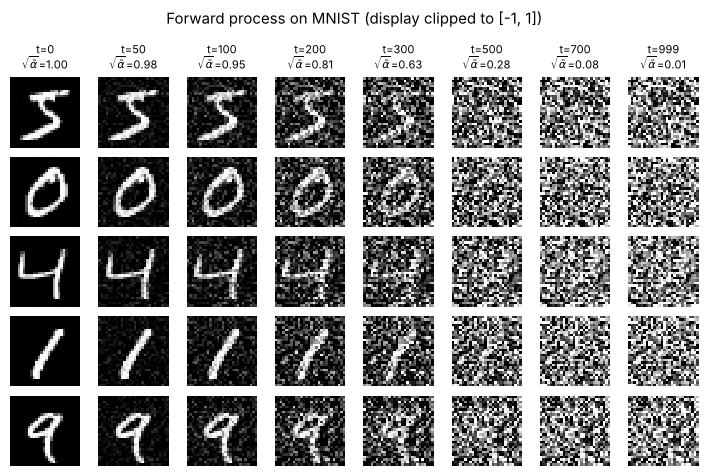

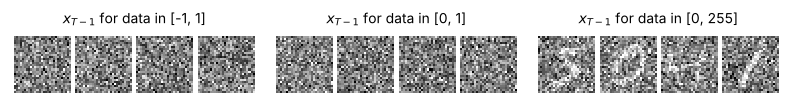

In [8]:
ts_show = [0, 50, 100, 200, 300, 500, 700, 999]
x0_show = x_train[:5].to(device)
eps_show = torch.randn_like(x0_show)              # the same noise at every t, so each row is one trajectory
fig, axes = plt.subplots(len(x0_show), len(ts_show), figsize=(7.2, 4.8))
for j, t in enumerate(ts_show):
    xt = schedule.q_sample(x0_show, torch.full((len(x0_show),), t, device=device), eps_show).cpu()
    for i in range(len(x0_show)):
        axes[i, j].imshow(xt[i, 0], cmap="gray", vmin=-1, vmax=1)
        axes[i, j].set_axis_off()
    axes[0, j].set_title(f"t={t}\n$\\sqrt{{\\bar\\alpha}}$={abar[t].sqrt():.2f}", fontsize=8)
fig.suptitle("Forward process on MNIST (display clipped to [-1, 1])")
plt.tight_layout()
plt.show()

# what x_{T-1} looks like if you forget to rescale the data
fig, axes = plt.subplots(1, 3, figsize=(8, 2.2))
for ax, (name, x) in zip(axes, scalings.items()):
    xT = abar[-1].sqrt() * x[:4] + (1 - abar[-1]).sqrt() * torch.randn_like(x[:4])
    dm.show_images(xT.float(), nrow=4, ax=ax, vmin=-2.5, vmax=2.5)
    ax.set_title(f"$x_{{T-1}}$ for data in {name}")
plt.tight_layout()
plt.show()

With data in $[-1,1]$, structure fades gradually: strokes are clear up to $t\approx100$, the digit is still
visible at $t\approx300$ and faint at $t\approx500$, and by $t\approx700$ the eye sees only noise. (Some low-frequency information
survives longer than the eye suggests, see section 6.) The second figure shows the scaling gotcha. Data in $[0,255]$
is still plainly visible at the last timestep, so the model would never be trained on the pure noise the sampler
starts from. Data in $[0,1]$ has a small variance, so SNR = 1 is reached much earlier, and fewer of the
1000 steps are spent at noise levels where the model still sees structure.

## 4 · Training, with every practical detail

The objective is the "simple" DDPM loss from notebook 02 (`dm.diffusion_loss`): draw a minibatch, draw
**an independent $t\sim\mathcal{U}\{0,\dots,T-1\}$ for every sample**, noise, predict $\epsilon$, take the MSE. The rest is engineering:

| ingredient | value here | why |
|---|---|---|
| optimiser | AdamW, lr $2\cdot10^{-4}$, no weight decay | the standard DDPM setting for small U-Nets. Adam's per-parameter scaling copes with very different gradient scales across layers |
| warm-up | lr ramps up linearly over the first 200 steps | Adam's second-moment estimates are poor at first, and large early steps on freshly switched-on residual branches can destabilise training |
| gradient clipping | global norm ≤ 1 | caps the influence of unusually large gradients (unlucky batches, early training) on Adam's moment estimates. Adam divides by a running RMS of the gradients, so a *uniform* rescaling changes little; clipping only bites on outliers. Cheap insurance |
| batch size | 64 | same as the reference checkpoints. Larger batches mostly reduce the loss noise from random $t$ |
| random $t$ per sample | uniform | every minibatch is an unbiased estimate of the average over all noise levels. Stratified or low-discrepancy $t$ (VDM, Kingma et al. 2021) reduces the variance further |
| **EMA** of weights | decay 0.999, used for **sampling** | see below |
| mixed precision | bfloat16 autocast (`USE_AMP`) | convs and matmuls in bf16, while weights, optimiser state and the loss stay in float32 (on CUDA, autocast also keeps normalisation layers in float32; on CPU, GroupNorm runs in bf16). bf16 has float32's exponent range, so unlike float16 it needs no loss scaling. `dm.train_diffusion(amp=...)` does the same |
| checkpointing | model + EMA (with its update counter) + optimiser + LR scheduler + step | resuming without the optimiser state resets Adam's moments and causes a loss spike. Resuming without the EMA counter restarts the EMA warm-up below, which overwrites the average within a few steps |
| augmentation | none | augmentations must leave the data distribution unchanged, or the model learns to generate augmented data. A horizontally flipped 2 is not a digit |

**Why sample with EMA weights?** With a constant learning rate, SGD does not converge to a point. It keeps jittering
around the optimum, with a spread set by the learning rate and the gradient noise. The exponential moving average

$$\theta^{\mathrm{EMA}}_n=d\,\theta^{\mathrm{EMA}}_{n-1}+(1-d)\,\theta_n=(1-d)\sum_{k=1}^{n}d^{\,n-k}\theta_k+d^{\,n}\theta_0,\qquad \theta^{\mathrm{EMA}}_0=\theta_0,$$

averages the last $\approx 1/(1-d)$ iterates (an exponentially weighted cousin of Polyak–Ruppert averaging),
which cancels much of that jitter.
Diffusion sampling applies the network hundreds of times, so small weight noise compounds into visible artefacts.
EMA weights are therefore what everyone samples with, while the raw weights are what the optimiser keeps
training. **Gotcha:** the $d^{\,n}\theta_0$ term means that early on a plain EMA is dominated by the random
initialisation. `dm.EMA` uses the warm-up $d_n=\min\{d,\,(1+n)/(10+n)\}$, whose horizon $\approx(10+n)/9$ grows
with $n$. It only reaches $d=0.999$ after about 9000 steps, so in a short run the EMA averages over just the last
few hundred steps.

**Another image gotcha: broadcasting.** Per-sample schedule coefficients have shape `(B,)` and must be reshaped
to `(B, 1, 1, 1)` before they multiply a `(B, C, H, W)` batch (`NoiseSchedule._bcast` does this). Broadcasting
aligns *trailing* dimensions, so a bare `(B,)` coefficient silently scales image *columns* when `B == W`, and a
`(B, 1)` coefficient silently scales image *rows* when `B == H`. Neither raises an error; with batch size 28 on
MNIST both happen.

The training loop below is written as a function, so that the exercises can reuse it for other networks.

In [9]:
def warmup_factor(step):
    """Linear learning-rate warm-up over the first WARMUP steps (a function, not a lambda, so it can be rebuilt)."""
    return min(1.0, (step + 1) / WARMUP)


def train(net, steps, data, state=None, ema_decay=0.999):
    """Train `net` in place. Returns (state, log) with state = (opt, lr_sched, ema).
    Pass a previous `state` to continue a run (e.g. one restored from a checkpoint)."""
    if state is None:
        opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=0.0)
        state = (opt, torch.optim.lr_scheduler.LambdaLR(opt, warmup_factor), dm.EMA(net, decay=ema_decay))
    opt, lr_sched, ema = state
    log, log_every, t_start = {"loss": [], "grad_norm": []}, max(1, steps // 6), time.time()
    net.train()
    for step in range(steps):
        x0 = data[torch.randint(0, len(data), (BATCH,), device=data.device)]
        with autocast():
            loss = dm.diffusion_loss(net, x0, schedule)       # random t per sample, eps-prediction MSE
        opt.zero_grad(set_to_none=True)
        loss.backward()
        grad_norm = nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)  # returns the norm *before* clipping
        opt.step()
        lr_sched.step()
        ema.update(net)                                       # after every optimiser step
        log["loss"].append(loss.item())
        log["grad_norm"].append(grad_norm.item())
        if step == 0 or (step + 1) % log_every == 0:
            print(f"step {step + 1:5d} | loss (last {log_every}) {np.mean(log['loss'][-log_every:]):.4f} | "
                  f"lr {lr_sched.get_last_lr()[0]:.1e} | {time.time() - t_start:5.0f}s")
    net.eval()
    log["seconds"] = time.time() - t_start
    return state, log


dm.seed_everything(0)
data = x_train.to(device)
model = dm.UNet(**dm.MNIST_RECIPE).to(device)       # `model` keeps the raw (optimiser) weights
state, log = train(model, TRAIN_STEPS, data)
opt, lr_sched, ema = state
print(f"\n{TRAIN_STEPS} steps in {log['seconds'] / 60:.1f} min ({TRAIN_STEPS / log['seconds']:.1f} steps/s on {device})")
print(f"first-step loss {log['loss'][0]:.3f}  (zero-initialised output => E||eps||^2/784 = 1)")
assert abs(log["loss"][0] - 1) < 0.15

step     1 | loss (last 250) 0.9928 | lr 2.0e-06 |     0s


step   250 | loss (last 250) 0.4264 | lr 2.0e-04 |    76s


step   500 | loss (last 250) 0.0338 | lr 2.0e-04 |   154s


step   750 | loss (last 250) 0.0305 | lr 2.0e-04 |   231s


step  1000 | loss (last 250) 0.0283 | lr 2.0e-04 |   308s


step  1250 | loss (last 250) 0.0271 | lr 2.0e-04 |   386s


step  1500 | loss (last 250) 0.0270 | lr 2.0e-04 |   463s

1500 steps in 7.7 min (3.2 steps/s on cpu)
first-step loss 0.993  (zero-initialised output => E||eps||^2/784 = 1)


**Checkpointing.** Save everything that defines the run's state: config, raw weights, EMA weights *and* the EMA's
update counter, optimiser and scheduler state, step. Then check that a restored run is the same run.

In [10]:
def save_checkpoint(path, net, state, step, losses):
    """Everything needed to resume training *and* to sample (EMA weights + config).
    Only tensors and plain Python types, so that it loads with torch.load(..., weights_only=True)."""
    opt, lr_sched, ema = state
    torch.save({"config": net.config, "model": net.state_dict(), "ema": ema.model.state_dict(),
                "ema_decay": ema.decay, "ema_updates": ema.num_updates, "opt": opt.state_dict(),
                "lr_sched": lr_sched.state_dict(), "step": step, "losses": torch.tensor(losses)}, path)


def resume(path):
    """Rebuild (net, state, checkpoint) from a checkpoint, ready for `train(net, more_steps, data, state)`."""
    ck = torch.load(path, map_location=device, weights_only=True)   # never unpickle arbitrary objects
    net = dm.UNet(**ck["config"]).to(device)
    net.load_state_dict(ck["model"])
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=0.0)
    opt.load_state_dict(ck["opt"])
    lr_sched = torch.optim.lr_scheduler.LambdaLR(opt, warmup_factor)
    lr_sched.load_state_dict(ck["lr_sched"])
    ema = dm.EMA(net, decay=ck["ema_decay"])
    ema.model.load_state_dict(ck["ema"])
    ema.num_updates = ck["ema_updates"]       # forget this and the EMA warm-up starts again from scratch
    return net, (opt, lr_sched, ema), ck


# FAST smoke tests write to a temporary file instead of checkpoints/
CKPT_PATH = (Path(tempfile.gettempdir()) / "05_my_unet_fast.pt") if FAST else dm.CKPT_DIR / "05_my_unet.pt"
CKPT_PATH.parent.mkdir(exist_ok=True)
save_checkpoint(CKPT_PATH, model, state, TRAIN_STEPS, log["loss"])
net2, state2, ck = resume(CKPT_PATH)
with torch.no_grad():
    xd, td = x_dummy.to(device), t_dummy.to(device)
    same = torch.equal(state2[2].model(xd, td), ema.model(xd, td)) and torch.equal(net2(xd, td), model(xd, td))
print(f"saved {CKPT_PATH.name}; restored raw + EMA models reproduce the in-memory ones exactly: {same}")
print(f"restored: step {ck['step']}, EMA updates {state2[2].num_updates}, lr {state2[1].get_last_lr()[0]:.1e}")

# The gotcha, measured: one more EMA update with the restored counter vs with a fresh EMA object (counter = 0)
fresh = dm.EMA(net2, decay=ck["ema_decay"])
fresh.model.load_state_dict(ck["ema"])
with torch.no_grad():
    for name, e in [("restored counter", copy.deepcopy(state2[2])), ("counter reset to 0", fresh)]:
        before = [p.clone() for p in e.model.parameters()]
        e.update(net2)   # moves the average a fraction (1 - d) of the way towards the raw weights
        moved = sum((p - b).norm() ** 2 for p, b in zip(e.model.parameters(), before)).sqrt()
        gap = sum((q - b).norm() ** 2 for q, b in zip(net2.parameters(), before)).sqrt()
        print(f"{name:18s}: one EMA update moves the average {(moved / gap).item():5.1%} of the way to the raw weights")

saved 05_my_unet.pt; restored raw + EMA models reproduce the in-memory ones exactly: True
restored: step 1500, EMA updates 1500, lr 2.0e-04


restored counter  : one EMA update moves the average  0.6% of the way to the raw weights
counter reset to 0: one EMA update moves the average 81.8% of the way to the raw weights


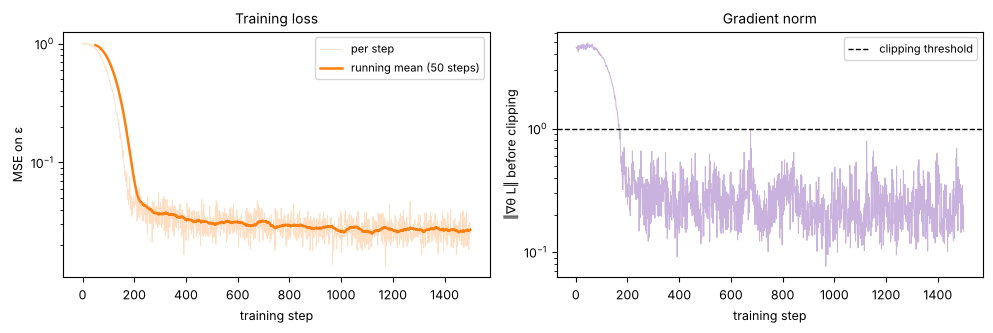

In [11]:
def running_mean(v, w):
    v = np.asarray(v)
    w = max(1, min(w, len(v)))
    return np.convolve(v, np.ones(w) / w, mode="valid")


steps_axis = np.arange(1, TRAIN_STEPS + 1)
w = max(1, min(50, TRAIN_STEPS // 10))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(steps_axis, log["loss"], color=C_MINE, alpha=0.25, lw=0.6, label="per step")
axes[0].plot(steps_axis[len(steps_axis) - len(running_mean(log["loss"], w)):], running_mean(log["loss"], w),
             color=C_MINE, lw=1.8, label=f"running mean ({w} steps)")
axes[0].set(yscale="log", xlabel="training step", ylabel="MSE on ε", title="Training loss")
axes[0].legend()
axes[1].plot(steps_axis, log["grad_norm"], color="tab:purple", alpha=0.5, lw=0.7)
axes[1].axhline(1.0, color="k", ls="--", lw=1, label="clipping threshold")
axes[1].set(yscale="log", xlabel="training step", ylabel="‖∇θ L‖ before clipping", title="Gradient norm")
axes[1].legend()
plt.tight_layout()
plt.show()

The loss starts at 1 (the zero-initialised output, as predicted). It barely moves while the warm-up learning rate
is tiny, then plunges, and then declines slowly. That long slow tail is where sample quality is made. The
per-step loss stays noisy forever. The noise is not a sign of a bad learning rate: each minibatch has a different
mix of $t$, and the loss depends strongly on $t$ (we will measure this below). The gradient norm is large during the
initial plunge, so clipping is active then. Afterwards it sits below the threshold, and clipping only catches
occasional spikes.

**Samples from the model we just trained.** We use DDIM with 50 steps (notebook 04) and the same starting noise
for the raw and the EMA weights. On the CPU budget of 1500 steps, expect rough results: digit-like strokes and
blobs, some recognisable digits, many malformed ones. That is honest for this little compute. On a GPU, raise
`TRAIN_STEPS` to about 20 000 (≈ 10 min) and the samples become clean.

DDIM-50: 512 samples per model, 45.2s each


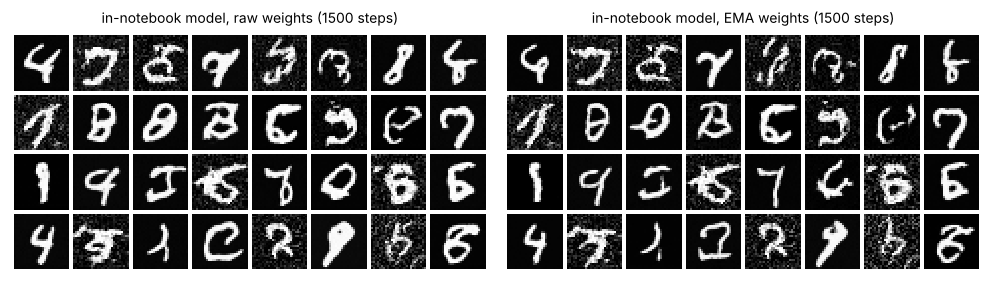

In [12]:
SAMPLE_BS = 256


@torch.no_grad()
def sample_ddim(net, n, steps=50, seed=0, clip=1.0, eta=0.0):
    """n DDIM samples (deterministic for eta=0: `seed` fixes x_T), in batches, under autocast. Returns CPU."""
    g = torch.Generator().manual_seed(seed)
    out = []
    for i in range(0, n, SAMPLE_BS):
        x_T = torch.randn(min(SAMPLE_BS, n - i), 1, 28, 28, generator=g).to(device)
        with autocast():
            x = dm.ddim_sample(net, schedule, x_T.shape, n_steps=steps, eta=eta, x_T=x_T, clip_x0=clip)
        out.append(x.float().cpu())
    return torch.cat(out)


mine_raw = sample_ddim(model, N_EVAL, seed=10)        # raw (optimiser) weights
t0 = time.time()
mine_ema = sample_ddim(ema.model, N_EVAL, seed=10)    # EMA weights, from the same starting noise x_T
print(f"DDIM-50: {N_EVAL} samples per model, {time.time() - t0:.1f}s each")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
dm.show_images(mine_raw[:32], nrow=8, ax=axes[0], title=f"in-notebook model, raw weights ({TRAIN_STEPS} steps)")
dm.show_images(mine_ema[:32], nrow=8, ax=axes[1], title=f"in-notebook model, EMA weights ({TRAIN_STEPS} steps)")
plt.tight_layout()
plt.show()

Compare the two grids position by position: the starting noise is the same. In a short run the EMA horizon is
only a few hundred steps (see the warm-up formula), so the two grids often look alike at first glance. Look at
the backgrounds and stroke edges. Section 7 measures the difference with Fréchet distances, which detect it more
reliably than the eye.

**From here on we use a longer-trained reference model** with the same architecture and recipe
(`dm.MNIST_RECIPE`, batch 64, the same loss and noise schedule). Normally that is
`checkpoints/mnist_unet_uncond.pt`, which `dm.load_or_train_mnist_model` loads, or trains and caches if it is
missing (minutes on a GPU, most of an hour on a CPU). On a CPU without that file we fall back to the model saved
by notebook 06 (`06_mnist_cond.pt`). It was trained with the same recipe, except that it was also given each
digit's class label, replaced by a special "no label" token 10% of the time. Called with `y=None` it receives that
token and is an *unconditional* model of the same digits (notebook 06 explains why). The cell prints which model
it loaded and how much longer than ours it was trained.

mnist_unet_uncond.pt not found: using 06_mnist_cond.pt, always called with y=None (unconditional)
reference model: 1,192,641 parameters, trained 4500 steps = 3.0x our 1500; config {'in_ch': 1, 'base_ch': 32, 'ch_mults': (1, 2, 2), 'n_res': 1, 'attn_levels': (2,), 'dropout': 0.0, 'n_classes': 10, 'out_ch': None}


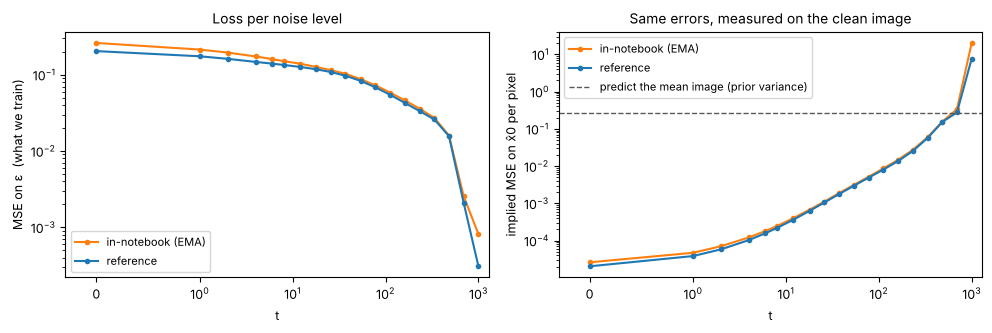

in-notebook (EMA)     : x0-MSE at t=999 = 20.169   (prior variance 0.269)
reference             : x0-MSE at t=999 = 7.620   (prior variance 0.269)


In [13]:
REF_CKPT = dm.CKPT_DIR / "mnist_unet_uncond.pt"   # the reference (made by pretrain_checkpoints.py, or by dm below)
ALT_CKPT = dm.CKPT_DIR / "06_mnist_cond.pt"       # same U-Net and recipe, saved while writing notebook 06
if REF_CKPT.exists() or GPU or not ALT_CKPT.exists():
    # loads the reference; if it is missing, dmtools trains and caches it first
    ref_model, ref_schedule = dm.load_or_train_mnist_model(conditional=False, device=device, batch_size=BATCH,
                                                           amp=USE_AMP)
    assert torch.allclose(ref_schedule.alpha_bars, schedule.alpha_bars)  # same noise schedule as ours
    # (in FAST mode dmtools trains a 300-step stand-in and does not save it)
    ref_steps = torch.load(REF_CKPT, map_location="cpu", weights_only=True)["steps"] if REF_CKPT.exists() else 300
else:
    ck_ref = torch.load(ALT_CKPT, map_location=device, weights_only=True)
    ref_model = dm.UNet(**ck_ref["config"]).to(device).eval()
    ref_model.load_state_dict(ck_ref["ema"])
    ref_steps = ck_ref["steps"]
    print(f"{REF_CKPT.name} not found: using {ALT_CKPT.name}, always called with y=None (unconditional)")
n_ref_params = sum(p.numel() for p in ref_model.parameters())  # (dm.count_params skips frozen EMA copies)
print(f"reference model: {n_ref_params:,} parameters, trained {ref_steps} steps "
      f"= {ref_steps / TRAIN_STEPS:.1f}x our {TRAIN_STEPS}; config {ref_model.config}")


@torch.no_grad()
def loss_per_t(net, x0, ts, seed=0):
    """Mean eps-MSE at each fixed t, with the same noise for every network (common random numbers).
    Runs in float32 on purpose: bf16 rounding of eps_hat would add ~1e-5 to the MSE, which is not negligible
    against the small eps-errors at large t."""
    vals = []
    for t in ts:
        torch.manual_seed(seed)
        vals.append(dm.diffusion_loss(net, x0, schedule, t=torch.full((len(x0),), int(t), device=device)).item())
    return np.array(vals)


ts_loss = np.unique(np.r_[0, np.geomspace(1, 999, 12 if FAST else 20).astype(int)])
x_eval = x_test[: (32 if FAST else 128)].to(device)
snr_t = (schedule.alpha_bars / (1 - schedule.alpha_bars)).cpu().numpy()[ts_loss]
curves = {"in-notebook (EMA)": (loss_per_t(ema.model, x_eval, ts_loss), C_MINE),
          "reference": (loss_per_t(ref_model, x_eval, ts_loss), C_DDPM)}
prior_var = x_train.var(dim=0).mean().item()   # MSE of the best *constant* guess, E[x0], per pixel

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, (eps_mse, c) in curves.items():
    axes[0].plot(ts_loss, eps_mse, "o-", ms=3, color=c, label=name)
    axes[1].plot(ts_loss, eps_mse / snr_t, "o-", ms=3, color=c, label=name)   # x0-MSE = eps-MSE / SNR(t)
axes[0].set(yscale="log", xlabel="t", ylabel="MSE on ε  (what we train)", title="Loss per noise level")
axes[1].axhline(prior_var, color=C_REAL, ls="--", lw=1, label="predict the mean image (prior variance)")
axes[1].set(yscale="log", xlabel="t", ylabel="implied MSE on x̂0 per pixel",
            title="Same errors, measured on the clean image")
for ax in axes:
    ax.set_xscale("symlog", linthresh=1)   # log-like axis that still shows t = 0
    ax.set_xlim(-0.3, 1300)
    ax.legend()
plt.tight_layout()
plt.show()
for name, (eps_mse, _) in curves.items():
    print(f"{name:22s}: x0-MSE at t=999 = {eps_mse[-1] / snr_t[-1]:.3f}   (prior variance {prior_var:.3f})")

Two views of the same errors. Since $x_0-\hat x_0=\sqrt{(1-\bar\alpha_t)/\bar\alpha_t}\,(\hat\epsilon-\epsilon)$,
the $\epsilon$-MSE is the $x_0$-MSE weighted by $\mathrm{SNR}(t)=\bar\alpha_t/(1-\bar\alpha_t)$.

* **Left:** the $\epsilon$-loss is largest at small $t$, where telling the tiny noise apart from fine image detail is
  hard, and almost zero at large $t$, where $x_t\approx\epsilon$. So uniform-$t$ training spends most of its
  gradient signal on low and intermediate noise levels. This **loss weighting** is a design choice, and
  later work tunes it (Kingma et al. 2021; Karras et al. 2022).
* **Right:** in image space the error grows with $t$. The Bayes-optimal denoiser's error would saturate at the
  dashed line, the **prior variance**: once $x_t$ carries no information, the posterior mean is the prior mean,
  "the average digit". A trained $\epsilon$-network can do *worse* than that at the largest $t$, and the printout
  compares the two at $t=999$. The reason is the weighting. An $x_0$-error there costs the $\epsilon$-loss only
  $\mathrm{SNR}(999)\approx4\cdot10^{-5}$ times as much, so the network is barely trained to get $\hat x_0$ right
  at those noise levels. Sampling hardly suffers, because $\hat x_0$ enters the early updates with a tiny weight.
  But it is one reason for **x0-clipping** (next section) and for alternative parameterisations such as
  $v$-prediction (Salimans & Ho 2022).
* Compare the two models: the gap between the curves shows at which noise levels the reference's longer
  training paid off. Look especially at the smallest $t$, where fine detail is restored, and at the largest.

## 5 · Sampling images: DDPM vs DDIM, the denoising chain, x0-clipping

Both samplers come from earlier notebooks: ancestral DDPM sampling with 1000 network evaluations (NFE, 02), and
deterministic DDIM with 50 (04). We run both with the reference model and time them.

one batch of 128 samples: DDPM-1000 1354 ms/sample, DDIM-50 62 ms/sample -> DDIM is 22x faster (ratio of network calls: 20)


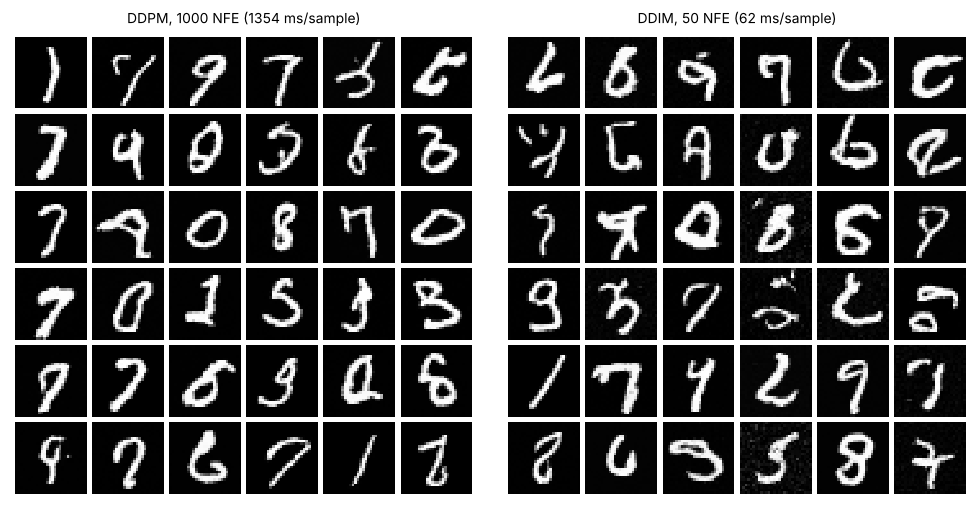

In [14]:
dm.seed_everything(1)
t0 = time.time()
with autocast():
    ddpm_x, ddpm_traj = dm.ddpm_sample(ref_model, schedule, (N_DDPM, 1, 28, 28), clip_x0=1.0,
                                       return_traj=True, traj_every=50)
ddpm_x = ddpm_x.float().cpu()
ddpm_sec = (time.time() - t0) / N_DDPM
# time DDIM on a batch of the same size: the cost per sample depends strongly on the batch size
t0 = time.time()
with autocast():
    dm.ddim_sample(ref_model, schedule, (N_DDPM, 1, 28, 28), n_steps=50, clip_x0=1.0)
ddim_sec = (time.time() - t0) / N_DDPM
print(f"one batch of {N_DDPM} samples: DDPM-1000 {1000 * ddpm_sec:.0f} ms/sample, DDIM-50 {1000 * ddim_sec:.0f} "
      f"ms/sample -> DDIM is {ddpm_sec / ddim_sec:.0f}x faster (ratio of network calls: 20)")
ddim_x = sample_ddim(ref_model, N_EVAL, steps=50, seed=2)   # more DDIM samples, for the evaluation in section 7

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
n_show = min(36, N_DDPM)
dm.show_images(ddpm_x[:n_show], nrow=6, ax=axes[0], title=f"DDPM, 1000 NFE ({1000 * ddpm_sec:.0f} ms/sample)")
dm.show_images(ddim_x[:36], nrow=6, ax=axes[1], title=f"DDIM, 50 NFE ({1000 * ddim_sec:.0f} ms/sample)")
plt.tight_layout()
plt.show()

Both grids look like handwriting, and DDIM costs 1/20 of the network calls. Both samplers were timed on the same
batch size, so the measured speed-up should be close to 20; the remaining difference comes from per-step overheads
(and from other programs competing for the machine). Expect a share of malformed digits from a 1.2M-parameter
model with this little training. Look closely at the backgrounds. If DDIM's samples keep some residual speckle that
DDPM's do not, that is a known difference. The deterministic ODE sampler carries every error of the network along
its path, while DDPM injects fresh noise at every step, which lets later steps correct earlier mistakes (Karras et
al. 2022 analyse this trade-off). Section 7 compares the two samplers quantitatively.

**Numerical precision.** We sampled under bfloat16 autocast. The schedule coefficients and the sampler arithmetic
stay in float32. This matters, because $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$
multiplies errors in $\hat\epsilon$ by $\sqrt{(1-\bar\alpha_t)/\bar\alpha_t}=1/\sqrt{\mathrm{SNR}(t)}$, which reaches
$\approx157$ at $t=999$. How much does bf16 change the samples? Run DDIM from the same $x_T$ in both precisions:

In [15]:
if USE_AMP:
    x_T = torch.randn(4 if FAST else 16, 1, 28, 28, generator=torch.Generator().manual_seed(3)).to(device)
    s32, tr32 = dm.ddim_sample(ref_model, schedule, x_T.shape, n_steps=50, x_T=x_T, return_traj=True)
    with autocast():
        s16, tr16 = dm.ddim_sample(ref_model, schedule, x_T.shape, n_steps=50, x_T=x_T, return_traj=True)
    diff = (s32.cpu() - s16.float().cpu()).abs()
    print(f"final samples, float32 vs bfloat16 from the same x_T: mean |diff| {diff.mean():.4f}, "
          f"max |diff| {diff.max():.3f}   (pixel range is 2)")
    for k in (0, len(tr32) // 2, len(tr32) - 1):
        d0 = (tr32[k][2] - tr16[k][2].float()).abs().mean().item()
        t_k = tr32[k][0]
        amp = (schedule.sqrt_one_minus_alpha_bars[t_k] / schedule.sqrt_alpha_bars[t_k]).item()
        print(f"x0_hat at t={t_k:3d}: mean |diff| {d0:.4f}   (eps errors amplified by sqrt((1-abar)/abar) = {amp:6.2f})")
else:
    print("USE_AMP is False: everything runs in float32, nothing to compare.")

final samples, float32 vs bfloat16 from the same x_T: mean |diff| 0.0043, max |diff| 0.405   (pixel range is 2)
x0_hat at t=999: mean |diff| 0.3317   (eps errors amplified by sqrt((1-abar)/abar) = 157.41)
x0_hat at t=489: mean |diff| 0.0106   (eps errors amplified by sqrt((1-abar)/abar) =   3.24)
x0_hat at t=  0: mean |diff| 0.0043   (eps errors amplified by sqrt((1-abar)/abar) =   0.01)


The final samples barely change: the mean pixel difference is a small fraction of the $[-1,1]$ range, so for
sampling bf16 is a nearly free speed-up. (A deterministic ODE sampler can still move a few pixels noticeably. Use
float32 when you need exact reproducibility, for example for DDIM inversion.) The intermediate $\hat x_0$
is a different story. At $t=999$ bf16 rounding of $\hat\epsilon$ is amplified about 157-fold, so the *prediction*
is visibly corrupted even though the sample is not: in the DDPM/DDIM update, $\hat x_0$ enters with a weight of
order $\sqrt{\bar\alpha}$, which cancels the amplification. (At smaller $t$ the printed differences also contain
the drift between the two trajectories, whose states $x_t$ no longer coincide, so they are not pure
amplification.) Whenever we *look at* $\hat x_0$ at large $t$ below, we
therefore recompute it in float32 from the stored states $x_t$. That costs one extra network call per snapshot.

### The denoising chain is coarse-to-fine

Each DDPM step also gives the model's current best guess $\hat x_0(x_t,t)=\mathbb{E}[x_0\mid x_t]$. Below are
$x_t$ and $\hat x_0$ along the DDPM chain for three of the samples above.

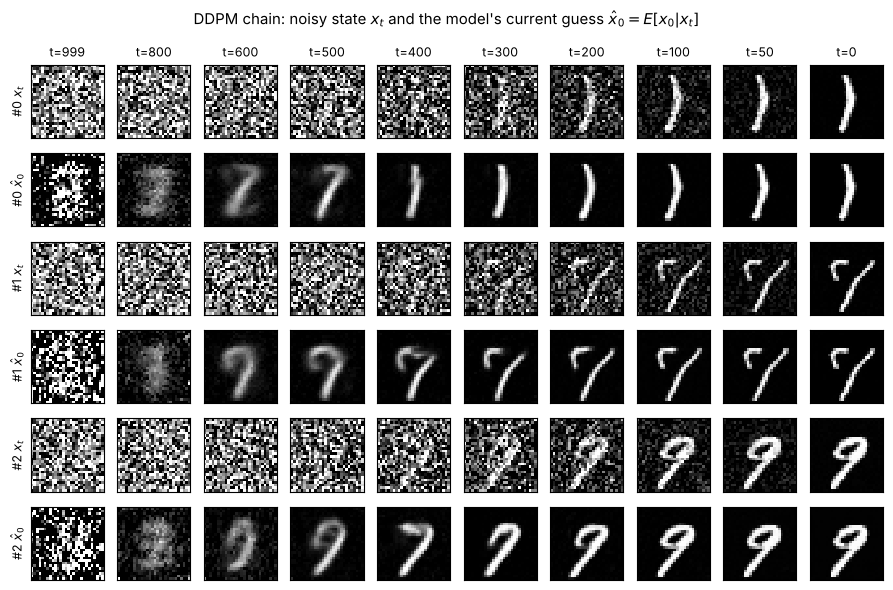

In [16]:
@torch.no_grad()
def x0_hat_fp32(net, x, t, bs=256, clip=1.0):
    """Recompute x0_hat(x_t, t) in float32 (clipped to [-clip, clip]) for a batch of stored states, on the CPU."""
    return torch.cat([dm.model_predictions(net, x[i:i + bs].to(device), t, schedule, clip_x0=clip)[1].cpu()
                      for i in range(0, len(x), bs)])


# replace the bf16 read-outs stored in the trajectory by float32 ones: (t, x_t, x0_hat)
ddpm_traj = [(t, xt, x0_hat_fp32(ref_model, xt, t)) for t, xt, _ in ddpm_traj]
traj_t = [t for t, _, _ in ddpm_traj]
cols = [999, 800, 600, 500, 400, 300, 200, 100, 50, 0]
fig, axes = plt.subplots(6, len(cols), figsize=(9, 6))
for r in range(3):
    for j, tc in enumerate(cols):
        _, xt, x0h = ddpm_traj[traj_t.index(tc)]
        for k, (im, lab) in enumerate([(xt, "$x_t$"), (x0h, "$\\hat x_0$")]):
            ax = axes[2 * r + k, j]
            ax.imshow(im[r, 0], cmap="gray", vmin=-1, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(f"#{r} {lab}", fontsize=9)
        axes[0, j].set_title(f"t={tc}", fontsize=9)
fig.suptitle("DDPM chain: noisy state $x_t$ and the model's current guess $\\hat x_0 = E[x_0|x_t]$")
plt.tight_layout()
plt.show()

Read the $\hat x_0$ rows from left to right. At the very largest $t$ the "guess" is not meaningful: as we saw in
section 4, the $\epsilon$-network's $\hat x_0$ is poor there, and clipping turns it into a saturated blob. Then a
blurry digit-like shape appears, which may still change identity for a while. By the middle of the chain the
**global shape is decided**, while $x_t$ itself still looks like noise to the eye. The last few hundred steps
only sharpen strokes. We can measure when the identity of the digit is fixed by classifying $\hat x_0$ at each
step and checking agreement with the class of the final sample:

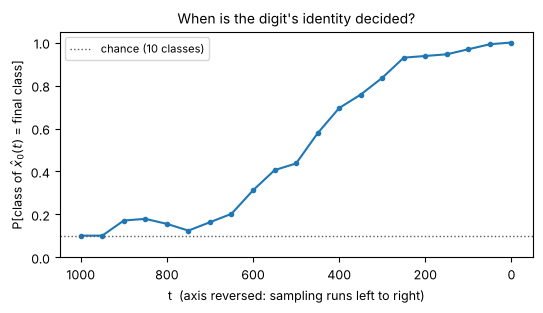

class of x0_hat agrees with the final class for >= 50% of samples from t = 450 on


In [17]:
clf = dm.load_or_train_classifier(device=device)


@torch.no_grad()
def classify(x, bs=1000):
    """Classifier probabilities for images in [-1, 1] (any device), returned on the CPU."""
    return torch.cat([clf(x[i:i + bs].to(device)).softmax(1).cpu() for i in range(0, len(x), bs)])


final_cls = classify(ddpm_x).argmax(1)
agree = [(classify(x0h.clamp(-1, 1)).argmax(1) == final_cls).float().mean().item() for _, _, x0h in ddpm_traj]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(traj_t, agree, "o-", color=C_DDPM, ms=3)
ax.axhline(0.1, color=C_REAL, ls=":", lw=1, label="chance (10 classes)")
ax.set(xlabel="t  (axis reversed: sampling runs left to right)", ylabel="P[class of $\\hat x_0(t)$ = final class]",
       title="When is the digit's identity decided?", ylim=(0, 1.05))
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()
t_half = next((t for t, a in zip(traj_t, agree) if a >= 0.5), None)
print(f"class of x0_hat agrees with the final class for >= 50% of samples from t = {t_half} on")

The curve stays near chance for the first part of the chain, then rises steeply and approaches 1 well before
the end. The class is settled around the middle of the chain (see the printed $t$), and the remaining steps change
details, not identity. One caveat: the classifier was trained on sharp digits, so on very blurry $\hat x_0$ its
answer is only a rough proxy for "what the model has committed to". Section 6 explains *why* generation is
coarse-to-fine.

### x0-clipping

The network predicts $\hat\epsilon$, and we convert it to $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$.
At large $t$ the factor $1/\sqrt{\bar\alpha_t}$ is huge, so small errors in $\hat\epsilon$ produce $\hat x_0$ far
outside the data range. Since we *know* $x_0\in[-1,1]^{784}$, we can clip $\hat x_0$ to that box. This is a
Euclidean projection onto a convex set, and it can only help. The true posterior mean $\mathbb{E}[x_0\mid x_t]$ is an
average of images in the box, so it lies in the box too, and projecting onto a convex set $C$ never increases the
distance to any point of $C$: $\|P_C(z)-y\|\le\|z-y\|$ for all $y\in C$. Clipping therefore leaves a Bayes-optimal
denoiser untouched and moves a wrong $\hat x_0$ closer to the right answer. (The box is much larger than the set of
digits, so clipping is a weak correction. It also means the sampler no longer follows the learned ODE exactly.)
`dm.model_predictions(..., clip_x0=1.0)` clips, then recomputes $\hat\epsilon$ from the
clipped $\hat x_0$ so that the pair stays consistent with $x_t$. Let's see how far out the raw predictions go along
an unclipped DDIM trajectory, and what clipping does to few-step sampling:

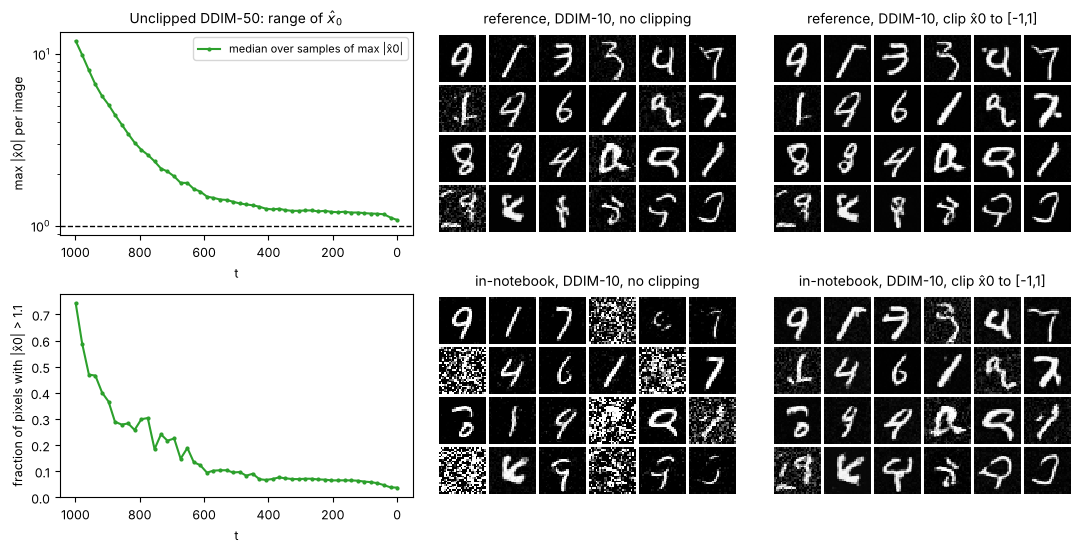

reference   DDIM-10, unclipped: 20.3% of samples off-manifold (farther from the training set than 99% of test digits)
reference   DDIM-10, clipped  : 10.9% of samples off-manifold (farther from the training set than 99% of test digits)


in-notebook DDIM-10, unclipped: 50.0% of samples off-manifold (farther from the training set than 99% of test digits)
in-notebook DDIM-10, clipped  : 29.7% of samples off-manifold (farther from the training set than 99% of test digits)


In [18]:
n_clip = 16 if FAST else 64
x_T = torch.randn(n_clip, 1, 28, 28, generator=torch.Generator().manual_seed(4)).to(device)
_, traj_nc = dm.ddim_sample(ref_model, schedule, x_T.shape, n_steps=50, x_T=x_T, return_traj=True)  # float32
t_nc = [t for t, _, _ in traj_nc]
frac_out = [(x0h.abs() > 1.1).float().mean().item() for _, _, x0h in traj_nc]
max_abs = [x0h.abs().amax(dim=(1, 2, 3)).median().item() for _, _, x0h in traj_nc]

few = {}
for net_name, net in [("reference", ref_model), ("in-notebook", ema.model)]:
    for clip in (None, 1.0):
        few[(net_name, clip)] = sample_ddim(net, n_clip, steps=10, seed=5, clip=clip)


@torch.no_grad()
def nearest_train(x, k=3, chunk=256):
    """L2 (pixel-space) k nearest neighbours of each image in the training set. Returns (dists, indices)."""
    xtr = x_train.flatten(1).to(device)
    dists, idxs = [], []
    for i in range(0, len(x), chunk):
        d = torch.cdist(x[i:i + chunk].flatten(1).to(device), xtr)
        v, j = d.topk(k, dim=1, largest=False)
        dists.append(v.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists), torch.cat(idxs)


# A simple failure detector (used again in section 7): a sample is "off-manifold" if it is farther from every
# training image than 99% of held-out test digits are.
nn_d_test, _ = nearest_train(x_test[:N_EVAL])
far = torch.quantile(nn_d_test[:, 0], 0.99).item()

fig = plt.figure(figsize=(11, 5.6))
gs = fig.add_gridspec(2, 3, width_ratios=[1.1, 1, 1])
ax = fig.add_subplot(gs[0, 0])
ax.plot(t_nc, max_abs, "o-", ms=2, color=C_DDIM, label="median over samples of max |x̂0|")
ax.axhline(1, color="k", ls="--", lw=1)
ax.set(yscale="log", xlabel="t", ylabel="max |x̂0| per image", title="Unclipped DDIM-50: range of $\\hat x_0$")
ax.invert_xaxis()
ax.legend()
ax = fig.add_subplot(gs[1, 0])
ax.plot(t_nc, frac_out, "o-", ms=2, color=C_DDIM)
ax.set(xlabel="t", ylabel="fraction of pixels with |x̂0| > 1.1", ylim=(0, None))
ax.invert_xaxis()
for i, net_name in enumerate(["reference", "in-notebook"]):
    for j, clip in enumerate((None, 1.0)):
        ax = fig.add_subplot(gs[i, 1 + j])
        dm.show_images(few[(net_name, clip)][:24], nrow=6, ax=ax,
                       title=f"{net_name}, DDIM-10, {'no clipping' if clip is None else 'clip x̂0 to [-1,1]'}")
plt.tight_layout()
plt.show()

for (net_name, clip), xs in few.items():
    off = (nearest_train(xs, k=1)[0][:, 0] > far).float().mean().item()
    print(f"{net_name:11s} DDIM-10, {'clipped  ' if clip else 'unclipped'}: {off:5.1%} of samples off-manifold "
          f"(farther from the training set than 99% of test digits)")

Early in the chain the unclipped $\hat x_0$ has values far outside $[-1,1]$, often by an order of magnitude. Only
as $t\to0$ does it settle near the data range. With only 10 sampling steps, every step jumps across a large range
of noise levels and leans heavily on $\hat x_0$, so these errors can leak into the samples. Some unclipped samples
may blow up into noise or speckle instead of a digit. Compare the columns and the printed off-manifold fractions
for the reference model and for the under-trained one. Clipping is a cheap fix that is on by default in most DDPM
code.

**Dynamic thresholding** (Imagen, Saharia et al. 2022) is a refinement. Per sample, let $s$ be the 99.5th
percentile of $|\hat x_0|$. If $s>1$, clip to $[-s,s]$ and divide by $s$. Static clipping saturates many pixels
when guidance pushes $\hat x_0$ far out (notebook 06); dynamic thresholding rescales instead. It is an exercise
below.

## 6 · Why coarse-to-fine? Diffusion as spectral autoregression

Sander Dieleman's observation (2024): look at images in the **Fourier domain**. Natural images, and digits, have a
power spectrum $P(f)$ that falls steeply with spatial frequency $f$. Gaussian noise is white: flat power at every
frequency. With an orthonormal FFT $\mathcal{F}$, noise and signal are independent, so

$$P_{x_t}(f)=\bar\alpha_t\,P_{x_0}(f)+(1-\bar\alpha_t),\qquad \mathrm{SNR}(f,t)=\frac{\bar\alpha_t\,P_{x_0}(f)}{1-\bar\alpha_t}.$$

As $t$ grows, the noise floor rises uniformly and **swamps the weak high frequencies first**. The low frequencies
survive longest. Run backwards, the reverse process must therefore produce low frequencies (global shape) first
and high frequencies (stroke edges) last. It is an approximate autoregression from coarse to fine.

The link to Bayesian denoising is direct, and it needs one correction first. The **mean image** $\mu=\mathbb{E}[x_0]$
is known before sampling starts (it is the posterior mean at $t=T-1$), so it is not information that the reverse
process has to *generate*. It also carries much of the low-frequency power of MNIST. So for the Bayesian analysis
we use the **centred** spectrum $P_c(f)$ of $x_0-\mu$, and $\mathrm{SNR}(f,t)=\bar\alpha_t P_c(f)/(1-\bar\alpha_t)$.

For a **Gaussian prior** $x_0\sim\mathcal{N}(\mu,\Sigma)$ the posterior is Gaussian, its mean is a linear function of
$x_t$, and its covariance follows from adding precisions ($x_t/\sqrt{\bar\alpha_t}$ is $x_0$ plus noise of variance
$(1-\bar\alpha_t)/\bar\alpha_t$). With the eigen-decomposition $\Sigma=\sum_i\lambda_iu_iu_i^\top$:

$$\mathrm{Cov}[x_0\mid x_t]=\Big(\Sigma^{-1}+\tfrac{\bar\alpha_t}{1-\bar\alpha_t}I\Big)^{-1}
  =\sum_i\frac{\lambda_i}{1+\mathrm{SNR}_i(t)}\,u_iu_i^\top,\qquad \mathrm{SNR}_i(t)=\frac{\bar\alpha_t\lambda_i}{1-\bar\alpha_t}.$$

Each principal component is shrunk independently, and its remaining error is a fraction $1/(1+\mathrm{SNR}_i)$ of its
prior variance. This posterior mean is also the **best linear (affine) denoiser** for *any* prior with mean $\mu$ and
covariance $\Sigma$. If the image statistics were **stationary** (the same at every position), the eigenvectors $u_i$
would be Fourier modes and the $\lambda_i$ the power spectrum. We would get the classical **Wiener filter**, with
relative error per frequency

$$\frac{\mathbb{E}\,|\mathcal{F}(\hat x_0-x_0)(f)|^2}{P_c(f)}=\frac{1}{1+\mathrm{SNR}(f,t)},$$

so a frequency is "decided" (error below 1/2) once its SNR exceeds 1. MNIST is not stationary (digits are centred,
the border is always black), so the full-covariance Gaussian, whose error per frequency is the diagonal of
$\mathcal{F}\,\mathrm{Cov}[x_0\mid x_t]\,\mathcal{F}^{H}$, does better. That gives three levels of prior knowledge:
**stationary Gaussian** (Wiener) $\to$ **Gaussian with the true mean and covariance** (best linear filter) $\to$
**the true, non-Gaussian prior** (Bayes-optimal, nonlinear). A perfect diffusion model attains the last one. Below
we (a) measure spectra of noised MNIST, (b) compute the two Gaussian predictions, and (c) measure the actual
reverse chain of the reference model. In (c), the final sample plays the role of $x_0$, and each $\hat x_0(t)$
(clipped to $[-1,1]$, as in the sampler) is measured against it.

In [19]:
H = 28
fy, fx = torch.fft.fftfreq(H), torch.fft.fftfreq(H)
R_BIN = (torch.sqrt(fy[:, None] ** 2 + fx[None, :] ** 2) * H).round().long()   # radius in cycles per image
FREQS = np.arange(1, H // 2 + 1)                                                # skip DC, stop at Nyquist (14)


def radial_average(P):
    """(..., H, W) array of per-frequency values -> (..., len(FREQS)) averages over rings of equal |f|."""
    return np.stack([P[..., R_BIN == k].mean(-1).numpy() for k in FREQS], axis=-1)


def power_spectrum(x):
    """Radially averaged power spectrum of a batch of images (B, 1, H, W), orthonormal FFT, batch-averaged."""
    return radial_average(torch.fft.fft2(x.cpu().double(), norm="ortho").abs().pow(2).mean(dim=(0, 1)))


x_spec = x_train[:2000]
P0 = power_spectrum(x_spec)
# checks: white noise is flat at 1, and noised data obeys P_xt = abar * P_x0 + (1 - abar)
P_noise = power_spectrum(torch.randn(2000, 1, H, H))
t_chk = 300
xt_chk = schedule.q_sample(x_spec.to(device), torch.full((len(x_spec),), t_chk, device=device)).cpu()
pred = abar[t_chk].item() * P0 + (1 - abar[t_chk].item())
print(f"white noise power: min {P_noise.min():.3f}, max {P_noise.max():.3f} (should be ~1)")
print(f"P_xt vs abar*P_x0 + (1-abar) at t={t_chk}: max relative error "
      f"{np.max(np.abs(power_spectrum(xt_chk) - pred) / pred):.3f}")

# The Gaussian prior fitted to MNIST: mean image and full 784 x 784 pixel covariance
x_gauss = x_train[: (5000 if FAST else 20_000)].double()
mu_img = x_gauss.mean(0, keepdim=True)
Xc = (x_gauss - mu_img).flatten(1)
lam, U = torch.linalg.eigh(Xc.T @ Xc / len(Xc))               # principal components of the digits
lam = lam.clamp(min=0)
FU2 = torch.fft.fft2(U.T.reshape(784, H, H), norm="ortho").abs().pow(2)  # |F u_i|^2 at every frequency
P_c = radial_average(torch.einsum("i,ihw->hw", lam, FU2))    # centred spectrum = diag(F Sigma F^H), averaged
P_raw = power_spectrum(x_gauss)
print(f"centred spectrum: from the eigen-decomposition vs directly, max relative difference "
      f"{np.max(np.abs(P_c / power_spectrum(x_gauss - mu_img) - 1)):.1e}")
print("share of the raw power due to the mean image at f = 1, 2, 3, 4:", np.round(1 - P_c[:4] / P_raw[:4], 2))

white noise power: min 0.990, max 1.007 (should be ~1)
P_xt vs abar*P_x0 + (1-abar) at t=300: max relative error 0.013


centred spectrum: from the eigen-decomposition vs directly, max relative difference 5.3e-15
share of the raw power due to the mean image at f = 1, 2, 3, 4: [0.8  0.16 0.05 0.06]


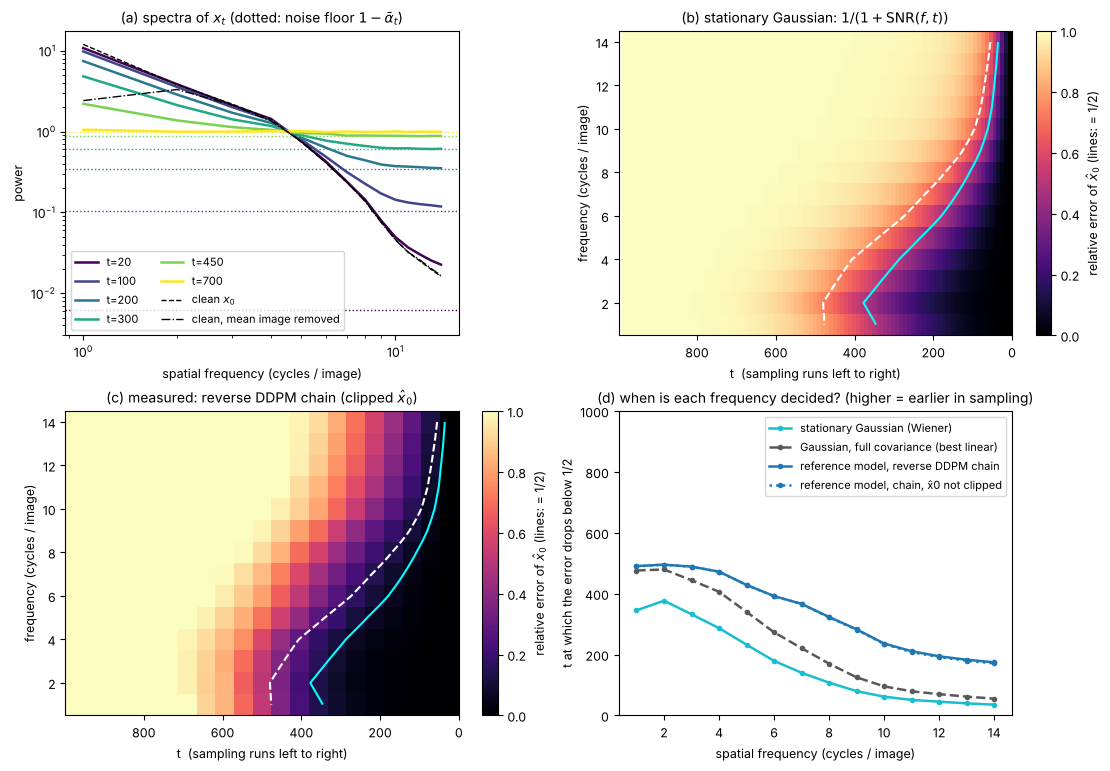

stationary Gaussian (Wiener)            : decided at t =  345  377  287  179   80   36   (f = 1, 2, 4, 6, 9, 14)
Gaussian, full covariance (best linear) : decided at t =  476  480  406  273  125   55   (f = 1, 2, 4, 6, 9, 14)
reference model, reverse DDPM chain     : decided at t =  491  496  473  392  283  174   (f = 1, 2, 4, 6, 9, 14)
reference model, chain, x̂0 not clipped : decided at t =  490  495  472  392  282  171   (f = 1, 2, 4, 6, 9, 14)


In [20]:
def decision_time(err, ts):
    """Per frequency: the t (in sampling order, i.e. from large to small t) at which the relative error first drops
    below 1/2, linearly interpolated between grid points. err: (n_freq, len(ts))."""
    order = np.argsort(ts)[::-1]
    ts, err = np.asarray(ts, dtype=float)[order], err[:, order]
    out = np.full(len(err), np.nan)
    for f, e in enumerate(err):
        k = int(np.argmax(e < 0.5))
        if e[k] < 0.5:   # (otherwise the frequency is never decided: NaN)
            out[f] = ts[0] if k == 0 else ts[k - 1] + (e[k - 1] - 0.5) / (e[k - 1] - e[k]) * (ts[k] - ts[k - 1])
    return out


t_grid = np.arange(0, 1000, 10)
ab_grid = abar[t_grid]                                                        # float64 tensor
snr_ft = ab_grid.numpy()[None, :] * P_c[:, None] / (1 - ab_grid.numpy()[None, :])   # (freq, t), stationary
wiener_err = 1 / (1 + snr_ft)
post_var = lam[None, :] / (1 + ab_grid[:, None] * lam[None, :] / (1 - ab_grid[:, None]))  # (t, components)
gauss_err = (radial_average(torch.einsum("ti,ihw->thw", post_var, FU2)) / P_c).T          # (freq, t)

# measured: per-frequency error of the chain's x0_hat(t) against the final sample, relative to the centred spectrum
P_final_c = power_spectrum(ddpm_x - ddpm_x.mean(0, keepdim=True))
chain_err = np.stack([power_spectrum(x0h - ddpm_x) / P_final_c for _, _, x0h in ddpm_traj], axis=1)  # (freq, snaps)
# the same without clipping x0_hat (clipping can only move x0_hat towards any image in [-1, 1], incl. the sample)
chain_err_nc = np.stack([power_spectrum(x0_hat_fp32(ref_model, xt, t, clip=None) - ddpm_x) / P_final_c
                         for t, xt, _ in ddpm_traj], axis=1)
t_dec = {"stationary Gaussian (Wiener)": (decision_time(wiener_err, t_grid), "tab:cyan", "-"),
         "Gaussian, full covariance (best linear)": (decision_time(gauss_err, t_grid), "0.35", "--"),
         "reference model, reverse DDPM chain": (decision_time(chain_err, traj_t), C_DDPM, "-"),
         "reference model, chain, x̂0 not clipped": (decision_time(chain_err_nc, traj_t), C_DDPM, ":")}

fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), layout="constrained")
cmap = plt.get_cmap("viridis")
ax = axes[0, 0]
for i, t in enumerate([20, 100, 200, 300, 450, 700]):
    c = cmap(i / 5)
    xt = schedule.q_sample(x_spec[:500].to(device), torch.full((500,), t, device=device)).cpu()
    ax.plot(FREQS, power_spectrum(xt), "-", color=c, lw=1.8, label=f"t={t}")
    ax.axhline(1 - abar[t].item(), color=c, ls=":", lw=1)
ax.plot(FREQS, P0, "k--", lw=1, label="clean $x_0$")
ax.plot(FREQS, P_c, "k-.", lw=1, label="clean, mean image removed")
ax.set(xscale="log", yscale="log", ylim=(3e-3, None), xlabel="spatial frequency (cycles / image)", ylabel="power",
       title="(a) spectra of $x_t$ (dotted: noise floor $1-\\bar\\alpha_t$)")
ax.legend(ncol=2)
for ax, err, ts_, title in [(axes[0, 1], wiener_err, t_grid, "(b) stationary Gaussian: $1/(1+\\mathrm{SNR}(f,t))$"),
                            (axes[1, 0], chain_err, np.array(traj_t), "(c) measured: reverse DDPM chain (clipped $\\hat x_0$)")]:
    order = np.argsort(ts_)
    im = ax.imshow(np.clip(err[:, order], 0, 1), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1,
                   extent=[ts_.min(), ts_.max(), FREQS[0] - 0.5, FREQS[-1] + 0.5])
    ax.contour(t_grid, FREQS, wiener_err, levels=[0.5], colors="cyan", linewidths=1.5)
    ax.contour(t_grid, FREQS, gauss_err, levels=[0.5], colors="white", linewidths=1.5, linestyles="--")
    ax.set(xlabel="t  (sampling runs left to right)", ylabel="frequency (cycles / image)", title=title)
    ax.set_xlim(999, 0)
    fig.colorbar(im, ax=ax, label="relative error of $\\hat x_0$ (lines: = 1/2)")
ax = axes[1, 1]
for name, (td, c, ls) in t_dec.items():
    ax.plot(FREQS, td, ls, color=c, marker="o", ms=3, lw=1.8, label=name)
ax.set(xlabel="spatial frequency (cycles / image)", ylabel="t at which the error drops below 1/2",
       title="(d) when is each frequency decided? (higher = earlier in sampling)", ylim=(0, 1000))
ax.legend()
plt.show()
for name, (td, _, _) in t_dec.items():
    print(f"{name:40s}: decided at t = " + " ".join(f"{v:4.0f}" for v in td[[0, 1, 3, 5, 8, 13]])
          + "   (f = 1, 2, 4, 6, 9, 14)")

(a) The clean spectrum (dashed) falls by orders of magnitude from low to high frequency. Each noisy spectrum
follows it until it hits its noise floor (dotted), then goes flat. As $t$ grows the floor rises and the crossing
moves to lower frequencies. The dash-dotted line shows that the mean image accounts for much of the power at the
lowest frequencies (printed above). (b) In the stationary-Gaussian picture the region where a frequency is still
undetermined (bright) sweeps from high to low frequencies as $t$ grows; the cyan line is $\mathrm{SNR}(f,t)=1$.
The dashed white line is the same boundary for the full-covariance Gaussian. (c) The model's reverse chain shows
the same ordering: the boundary between "still open" (bright) and "settled" (dark) runs from low frequencies at
large $t$ (early in sampling) to high frequencies near the end.

(d) condenses this into one number per frequency, the noise level at which it is decided. Apart from the lowest
couple of frequencies, every curve falls with frequency: **coarse-to-fine is already a property of the Gaussian
predictions**, and the trained model follows it. Read the gaps between the curves as answers to separate questions. The gap from the stationary to the
full-covariance Gaussian is what knowing *where* digits sit (non-stationarity) is worth to a purely linear
denoiser. For a *perfect* model, the chain's curve would be the Bayes-optimal one for the true prior, which can only
lie above the full-covariance curve. Where the measured curve lies above it, the network decides a frequency band
earlier than *any* linear denoiser could, which points to non-Gaussian structure in the digits (for instance,
sharp stroke edges are largely implied by the coarse shape). Three caveats keep this honest. The chain is measured
against the model's *own* final samples, so a model that is less diverse than the data (overconfident) would also
look decisive. Clipping can only move $\hat x_0$ closer to the final sample, which is why the dotted, unclipped curve
is shown too. And the estimate is noisy: the chain was recorded every 50 steps, on `N_DDPM` samples. With these
caveats, read the printout: if the model's chain decides the middle and high frequencies well before the best linear
filter, and the unclipped curve lies on top of the clipped one, the network really is exploiting structure that no
Gaussian model of the digits has.

This is the spectral explanation of the coarse-to-fine chain in section 5. It also explains several
practical facts: why noise schedules matter so much (they decide how many steps are spent on each frequency
band), why higher-resolution images need schedules shifted towards more noise (neighbouring pixels are redundant,
so the same per-pixel noise hides less of the image), and why sampling with very few steps loses fine detail
first.

### What does the denoiser look at? Its Jacobian

A second view of the same idea, closer to Bayesian inference. Differentiate the posterior mean with respect to
the observation. Write $x_t=a\,x_0+s\,\epsilon$ with $a=\sqrt{\bar\alpha_t}$, $s^2=1-\bar\alpha_t$. Then
$p(x_0\mid x_t)\propto p(x_0)\exp\!\big(a\,x_0^\top x_t/s^2-a^2\|x_0\|^2/2s^2\big)$ is an exponential family in
$x_t$, and differentiating its mean gives its covariance ("second-order Tweedie"):

$$\frac{\partial\,\mathbb{E}[x_0\mid x_t]}{\partial x_t}=\frac{a}{s^2}\Big(\mathbb{E}[x_0x_0^\top\mid x_t]-\mathbb{E}[x_0\mid x_t]\,\mathbb{E}[x_0\mid x_t]^\top\Big)=\frac{\sqrt{\bar\alpha_t}}{1-\bar\alpha_t}\,\mathrm{Cov}[x_0\mid x_t].$$

So row $p$ of the denoiser's Jacobian is an **adaptive filter**: the weights with which pixel $p$ of $\hat x_0$
averages the noisy input. It is proportional to the posterior covariance of pixel $p$ with every other pixel.
Two predictions follow. The filter should widen as $t$ grows, which needs the U-Net's large receptive field.
And the Jacobian should be **symmetric** (positive semi-definite, too), although nothing in the architecture
enforces that. One subtlety for the symmetry test: $\hat x_0=(x_t-s\,\hat\epsilon)/a$ gives
$\partial\hat x_0/\partial x_t=(I-s\,\partial\hat\epsilon/\partial x_t)/a$, which contains the symmetric term
$I/a$ whatever the network computes. An untrained network would look "fairly symmetric" for free. So we measure
symmetry on the **off-diagonal** part of the Jacobian and compare a trained network with an untrained one.

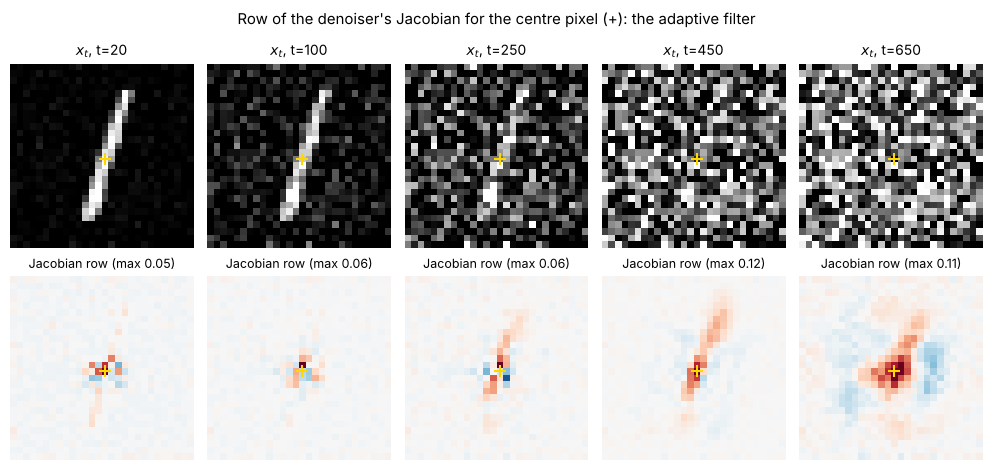

trained (reference)           t=300: off-diagonal asymmetry 0.610 | negative eigenvalue mass of the symmetric part 19.7%


untrained, same architecture  t=300: off-diagonal asymmetry 1.415 | negative eigenvalue mass of the symmetric part  0.0%
random Gaussian matrix              : off-diagonal asymmetry 1.417


In [21]:
def x0_hat_fn(net, t):
    """x -> x0_hat(x, t) for a fixed integer t (float32, differentiable)."""
    sa, s1a = schedule.sqrt_alpha_bars[t], schedule.sqrt_one_minus_alpha_bars[t]
    return lambda x: (x - s1a * net(x, torch.full((x.shape[0],), t, device=x.device))) / sa


def jacobian_rows(f, x, pixels, chunk=48):
    """Rows d f(x)[p] / d x for flat pixel indices p, using one copy of x per row in a single batch.
    This is valid only because samples in a batch do not interact (GroupNorm, not BatchNorm)."""
    rows = []
    for i in range(0, len(pixels), chunk):
        pix = pixels[i:i + chunk]
        X = x.repeat(len(pix), 1, 1, 1).requires_grad_(True)
        out = f(X).flatten(1)
        g, = torch.autograd.grad(out[torch.arange(len(pix), device=out.device), pix.to(out.device)].sum(), X)
        rows.append(g.flatten(1))
    return torch.cat(rows)


idx = int(torch.nonzero(x_test[:, 0, 14, 14] > 0.5)[0])   # a test digit with ink at the centre pixel
x_clean = x_test[idx:idx + 1].to(device)
p_centre = torch.tensor([14 * 28 + 14])
t_jac = [20, 100, 250, 450, 650]
noise = torch.randn(x_clean.shape, generator=torch.Generator().manual_seed(6)).to(device)
fig, axes = plt.subplots(2, len(t_jac), figsize=(10, 4.9))
for j, t in enumerate(t_jac):
    xt = schedule.q_sample(x_clean, torch.full((1,), t, device=device), noise)
    J_row = jacobian_rows(x0_hat_fn(ref_model, t), xt, p_centre)[0].view(28, 28).cpu()
    lim = J_row.abs().max().item()
    axes[0, j].imshow(xt[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    axes[0, j].set_title(f"$x_t$, t={t}")
    axes[1, j].imshow(J_row, cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[1, j].set_title(f"Jacobian row (max {lim:.2f})", fontsize=9)
    for r in range(2):
        axes[r, j].plot(14, 14, "+", color="gold", ms=8, mew=1.5)
        axes[r, j].set_axis_off()
fig.suptitle("Row of the denoiser's Jacobian for the centre pixel (+): the adaptive filter")
plt.tight_layout()
plt.show()

# symmetry check on the central 12x12 block of pixels (a 144 x 144 sub-matrix of the 784 x 784 Jacobian)
def offdiag_asymmetry(J):
    """||A - A^T|| / ||A|| for A = J without its diagonal (0: symmetric; ~1.41 for a random matrix)."""
    A = J - torch.diag(torch.diag(J))
    return ((A - A.T).norm() / A.norm()).item()


block_pix = torch.tensor([r * 28 + c for r in range(8, 20) for c in range(8, 20)])
t_sym = 300
xt = schedule.q_sample(x_clean, torch.full((1,), t_sym, device=device), noise)
untrained = copy.deepcopy(check_net).to(device).eval()   # section 2.4's U-Net, zero-init layers randomised
for name, net in [("trained (reference)", ref_model), ("untrained, same architecture", untrained)]:
    J = jacobian_rows(x0_hat_fn(net, t_sym), xt, block_pix).cpu()[:, block_pix].double()   # .cpu() first (MPS)
    eig = torch.linalg.eigvalsh((J + J.T) / 2)
    print(f"{name:29s} t={t_sym}: off-diagonal asymmetry {offdiag_asymmetry(J):.3f} | negative eigenvalue mass of "
          f"the symmetric part {eig.clamp(max=0).abs().sum() / eig.abs().sum():5.1%}")
A_rand = torch.randn(144, 144, dtype=torch.float64)
print(f"{'random Gaussian matrix':29s}       : off-diagonal asymmetry {offdiag_asymmetry(A_rand):.3f}")

At small $t$ the filter is a narrow spot around the pixel, so the model barely smooths. As $t$ grows it widens:
first along the stroke (an *adaptive*, orientation-dependent smoothing that no fixed linear filter performs),
then over a large part of the digit, often with negative side lobes. At large $t$ one output pixel depends on
input pixels far away, which a few 3×3 convolutions could never do. This is the "global context" requirement from
section 1, made visible. (At the very largest $t$ the filters of an $\epsilon$-network become erratic, for the
reason discussed in section 4, so we stop at $t=650$.)

The symmetry check compares the off-diagonal part of the Jacobian with its transpose. An untrained network of
the same architecture is about as asymmetric as a random matrix. The trained one is clearly more symmetric (compare
the printed values). The network was never told that its output is a posterior mean, i.e. that $\hat\epsilon$ is
proportional to the gradient of a log-density (notebook 03), and nothing in the architecture forces a symmetric
Jacobian. Training on the denoising objective pushes it towards that structure, and the remaining asymmetry
measures how far the network still is from an exact posterior mean. The negative eigenvalue mass should be
compared with 0, the value for an exact posterior covariance; a clearly non-zero value means the trained network's
Jacobian is not yet a valid covariance matrix. (The untrained network passes this test trivially, because its
Jacobian is dominated by the $I/a$ term.) Kadkhodaie et al. (2024)
build their analysis of generalisation on the eigen-decomposition of exactly these Jacobians.

## 7 · Evaluating image samples

On 2-D toy data we could compare samples with the true density (MMD, sliced Wasserstein). For images there is no
ground truth density, so practitioners use a toolbox of imperfect checks. We use three of them.

### 7a · Memorisation: nearest neighbours in the training set

A model that copies training images would have perfect "quality". For each generated sample, find its nearest
training image in pixel space. As a baseline, do the same for **held-out test images**: they are genuinely new
digits from the same distribution. If generated samples sit much closer to the training set than test images
do, the model memorises.

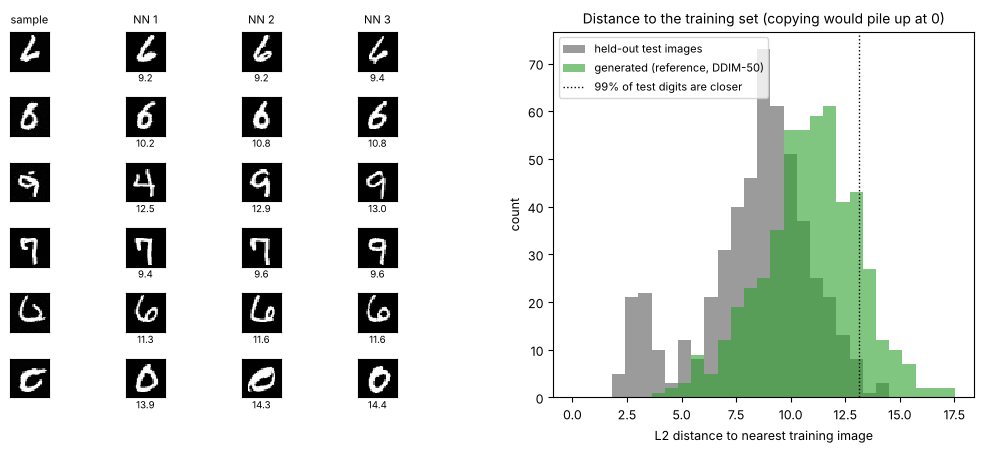

median NN distance: generated 11.00 | held-out test 8.78 | smallest generated 3.82 | smallest test 2.25
off-manifold (beyond the dotted line): generated 14.5%, test 1% by construction


In [22]:
nn_d_gen, nn_i_gen = nearest_train(ddim_x)   # nearest_train and nn_d_test were defined in section 5
n_rows = 6
fig = plt.figure(figsize=(10, 4.6))
gs = fig.add_gridspec(n_rows, 6, width_ratios=[1, 1, 1, 1, 0.5, 7.5])
for r in range(n_rows):
    ims = [ddim_x[r, 0]] + [x_train[nn_i_gen[r, k], 0] for k in range(3)]
    for c, im in enumerate(ims):
        ax = fig.add_subplot(gs[r, c])
        ax.imshow(im, cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if c > 0:
            ax.set_xlabel(f"{nn_d_gen[r, c - 1]:.1f}", fontsize=7, labelpad=1)
        if r == 0:
            ax.set_title("sample" if c == 0 else f"NN {c}", fontsize=8)
ax = fig.add_subplot(gs[:, 5])
bins = np.linspace(0, max(nn_d_gen[:, 0].max(), nn_d_test[:, 0].max()).item(), 30)
ax.hist(nn_d_test[:, 0].numpy(), bins=bins, alpha=0.6, color=C_REAL, label="held-out test images")
ax.hist(nn_d_gen[:, 0].numpy(), bins=bins, alpha=0.6, color=C_DDIM, label="generated (reference, DDIM-50)")
ax.axvline(far, color="k", ls=":", lw=1, label="99% of test digits are closer")
ax.set(xlabel="L2 distance to nearest training image", ylabel="count",
       title="Distance to the training set (copying would pile up at 0)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"median NN distance: generated {nn_d_gen[:, 0].median():.2f} | held-out test {nn_d_test[:, 0].median():.2f}"
      f" | smallest generated {nn_d_gen[:, 0].min():.2f} | smallest test {nn_d_test[:, 0].min():.2f}")
print(f"off-manifold (beyond the dotted line): generated {(nn_d_gen[:, 0] > far).float().mean():.1%}, "
      f"test 1% by construction")

The nearest neighbours (distances under each image) are similar digits written differently, not copies, and
no generated sample piles up near distance 0. With 60 000 training images and a small model this is the expected
regime: the model *generalises*. Kadkhodaie et al. (2024) show the transition: with few training images the same
architecture memorises (an exercise below). The generated histogram also tends to sit to the *right* of the test
histogram. That is the opposite of memorisation: imperfect samples (residual speckle, malformed strokes) are far
from every real digit, and the samples beyond the dotted line are the model's failures. Two caveats. Pixel-space L2
misses near-copies that are shifted by a pixel. And "no copies" is not the same as "good samples".

### 7b · Mode coverage: which digits does the model generate?

The unconditional model should generate all ten digits in roughly their training proportions. A model that
dropped a class could still produce beautiful samples. We classify the samples with the pre-trained MNIST
classifier and also record its confidence: low confidence indicates ambiguous or malformed digits.

test images           : mean confidence 0.981 | confident (p>0.9): 96.1% | class shares 7.4% to 13.5% | standard error of a bar ~ sqrt(0.1*0.9/n) = 1.3%
reference DDPM-1000   : mean confidence 0.880 | confident (p>0.9): 66.4% | class shares 3.1% to 18.0% | standard error of a bar ~ sqrt(0.1*0.9/n) = 2.7%


reference DDIM-50     : mean confidence 0.849 | confident (p>0.9): 56.8% | class shares 6.4% to 18.2% | standard error of a bar ~ sqrt(0.1*0.9/n) = 1.3%


in-notebook DDIM-50   : mean confidence 0.824 | confident (p>0.9): 52.9% | class shares 5.1% to 20.9% | standard error of a bar ~ sqrt(0.1*0.9/n) = 1.3%


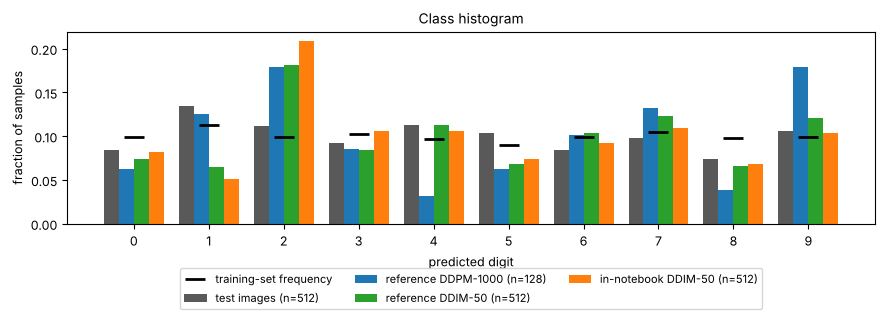

In [23]:
sets = {"test images": (x_test[:N_EVAL], C_REAL), "reference DDPM-1000": (ddpm_x, C_DDPM),
        "reference DDIM-50": (ddim_x, C_DDIM), "in-notebook DDIM-50": (mine_ema, C_MINE)}
train_freq = np.bincount(y_train.numpy(), minlength=10) / len(y_train)
fig, ax = plt.subplots(figsize=(9, 3.4))
width = 0.8 / len(sets)
for i, (name, (xs, c)) in enumerate(sets.items()):
    p = classify(xs)
    freq = np.bincount(p.argmax(1).numpy(), minlength=10) / len(xs)
    ax.bar(np.arange(10) + (i - 1.5) * width, freq, width, color=c, label=f"{name} (n={len(xs)})")
    conf = p.max(1).values
    print(f"{name:22s}: mean confidence {conf.mean():.3f} | confident (p>0.9): {(conf > 0.9).float().mean():.1%}"
          f" | class shares {freq.min():.1%} to {freq.max():.1%} | standard error of a bar "
          f"~ sqrt(0.1*0.9/n) = {np.sqrt(0.09 / len(xs)):.1%}")
ax.plot(np.arange(10), train_freq, "k_", ms=14, mew=2, label="training-set frequency")
ax.set(xticks=range(10), xlabel="predicted digit", ylabel="fraction of samples", title="Class histogram")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()

A missing mode would show up as a class share near 0 (the printout gives each set's smallest share). The
proportions are never perfect, so judge the deviations against sampling noise: a bar near 10% has a standard error
of about $\sqrt{0.1\cdot0.9/n}$ (printed for each set). Larger deviations mean either a real imbalance in the
model, or classifier confusion on malformed samples, which tend to land in a few "catch-all" classes. The printed confidences separate fidelity
from coverage. Compare each model's fraction of confidently classified samples with the test-image value: the gap
measures ambiguous or malformed digits.

### 7c · Fréchet distance in feature space (the idea behind FID)

**FID** (Heusel et al. 2017) summarises "how far is the sample distribution from the data distribution" in one
number. Embed real and generated images with a fixed, pre-trained network $\phi$. Fit a Gaussian to each set of
features, and compute the *squared* Fréchet (2-Wasserstein) distance $W_2^2$ between the two Gaussians, which has
a closed form:

$$\mathrm{FD}=\|\mu_r-\mu_g\|^2+\mathrm{Tr}\Big(\Sigma_r+\Sigma_g-2\big(\Sigma_r\Sigma_g\big)^{1/2}\Big).$$

Why features rather than pixels? Pixel-space statistics are dominated by low-level variation (stroke thickness,
small shifts) that says little about whether an image *looks right*. The features of a network trained for
recognition capture semantic and perceptual structure. FID proper uses the 2048-d pool features of an
ImageNet-trained Inception-v3. For MNIST those are a poor fit (natural-image features applied to digits), so we
use the 128-d penultimate layer of our MNIST classifier (`MNISTClassifier.features`). This is the
same idea, sometimes called a "Fréchet classifier distance".

A trace identity makes the matrix square root stable: $\mathrm{Tr}(\Sigma_r\Sigma_g)^{1/2}$ equals the sum of
square roots of the eigenvalues of the symmetric PSD matrix $\Sigma_r^{1/2}\Sigma_g\Sigma_r^{1/2}$ (a similar matrix).

In [24]:
def gaussian_stats(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)


def frechet_distance(mu1, S1, mu2, S2):
    """||mu1 - mu2||^2 + Tr(S1 + S2 - 2 (S1 S2)^(1/2)), via eigenvalues of S1^(1/2) S2 S1^(1/2)."""
    w, V = np.linalg.eigh(S1)
    sqrt_S1 = (V * np.sqrt(np.clip(w, 0, None))) @ V.T
    tr_sqrt = np.sqrt(np.clip(np.linalg.eigvalsh(sqrt_S1 @ S2 @ sqrt_S1), 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(S1) + np.trace(S2) - 2 * tr_sqrt)


# checks: (1) diagonal covariances have the closed form sum (sqrt(s1) - sqrt(s2))^2; (2) agree with scipy's sqrtm
rng = np.random.default_rng(0)
m1, m2, s1, s2 = rng.normal(size=5), rng.normal(size=5), rng.uniform(0.1, 2, 5), rng.uniform(0.1, 2, 5)
closed = ((m1 - m2) ** 2).sum() + ((np.sqrt(s1) - np.sqrt(s2)) ** 2).sum()
A, B = rng.normal(size=(6, 6)), rng.normal(size=(6, 6))
S1, S2 = A @ A.T, B @ B.T
via_scipy = np.trace(S1 + S2 - 2 * linalg.sqrtm(S1 @ S2).real)
print(f"diagonal case: ours {frechet_distance(m1, np.diag(s1), m2, np.diag(s2)):.6f} vs closed form {closed:.6f}")
print(f"general case : ours {frechet_distance(np.zeros(6), S1, np.zeros(6), S2):.6f} vs scipy.sqrtm {via_scipy:.6f}")


@torch.no_grad()
def features(x, bs=1000):
    return torch.cat([clf.features(x[i:i + bs].to(device)).cpu() for i in range(0, len(x), bs)])


n_ref = 2000 if FAST else 10_000
mu_ref, S_ref = gaussian_stats(features(x_train[:n_ref]))   # reference statistics from training images
f_test = features(x_test)

diagonal case: ours 5.086867 vs closed form 5.086867
general case : ours 23.845588 vs scipy.sqrtm 23.845588


**Pitfall 1: FD is biased upwards at small sample size.** Even two samples from the *same* distribution have
FD > 0, because the covariance estimated from $n$ points is noisy. A $d\times d$ covariance has $d(d+1)/2$ free
entries (about 8 000 for our $d=128$ features), so $n$ must be several times $d$ before the estimate settles; at
$n\le d$ the sample covariance is not even full rank. The bias shrinks roughly like $1/n$. Below we compute this
"floor" for held-out test images at several $n$, then compare models **at a common $n$**. For error bars we use the
bootstrap: recompute FD on resamples (with replacement) of the same $n$ samples, and take the standard deviation.

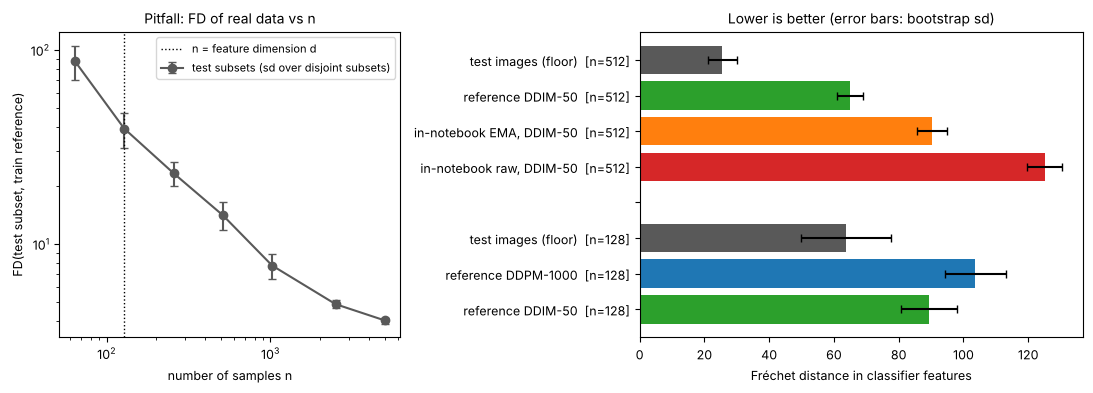

test images (floor)  [n=512]          : FD =   25.49 ±  4.46
reference DDIM-50  [n=512]            : FD =   65.07 ±  4.06
in-notebook EMA, DDIM-50  [n=512]     : FD =   90.22 ±  4.66
in-notebook raw, DDIM-50  [n=512]     : FD =  125.07 ±  5.32
test images (floor)  [n=128]          : FD =   63.74 ± 13.83
reference DDPM-1000  [n=128]          : FD =  103.68 ±  9.43
reference DDIM-50  [n=128]            : FD =   89.29 ±  8.60
check of the error bars at n = 512: bootstrap sd of the floor 4.46 vs sd over disjoint test subsets 2.33


In [25]:
def fd_of_subsets(feats, n, max_rep=10, seed=0):
    """FD against the training reference for up to max_rep disjoint random subsets of size n."""
    perm = np.random.default_rng(seed).permutation(len(feats))
    reps = min(max_rep, len(feats) // n)
    return np.array([frechet_distance(*gaussian_stats(feats[perm[i * n:(i + 1) * n]]), mu_ref, S_ref)
                     for i in range(reps)])


ns = [8, 32] if FAST else [64, 128, 256, 512, 1024, 2500, 5000]
floor = {n: fd_of_subsets(f_test, n) for n in ns}

def fd_with_bootstrap(feats, n, reps=10, seed=0):
    """FD of the first n feature vectors against the training reference, and its bootstrap sd."""
    f, rng = feats[:n], np.random.default_rng(seed)
    boot = [frechet_distance(*gaussian_stats(f[torch.from_numpy(rng.integers(0, n, n))]), mu_ref, S_ref)
            for _ in range(reps)]
    return frechet_distance(*gaussian_stats(f), mu_ref, S_ref), np.std(boot)


feats = {"test images (floor)": (f_test, C_REAL), "reference DDPM-1000": (features(ddpm_x), C_DDPM),
         "reference DDIM-50": (features(ddim_x), C_DDIM), "in-notebook EMA, DDIM-50": (features(mine_ema), C_MINE),
         "in-notebook raw, DDIM-50": (features(mine_raw), "tab:red")}
# Two comparisons, each at its own common n: everything sampled with DDIM-50 at n = N_EVAL, and the expensive
# DDPM-1000 set against DDIM-50 at n = N_DDPM.
groups = [(N_EVAL, ["test images (floor)", "reference DDIM-50", "in-notebook EMA, DDIM-50", "in-notebook raw, DDIM-50"]),
          (N_DDPM, ["test images (floor)", "reference DDPM-1000", "reference DDIM-50"])]
rows = []   # (label, fd, sd, colour), with an empty row between the groups
for n, names in groups:
    rows += [(f"{k}  [n={n}]", *fd_with_bootstrap(feats[k][0], n), feats[k][1]) for k in names] + [("", np.nan, np.nan, "w")]
rows = rows[:-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].errorbar(ns, [floor[n].mean() for n in ns], yerr=[floor[n].std() for n in ns], fmt="o-", color=C_REAL,
                 capsize=3, label="test subsets (sd over disjoint subsets)")
axes[0].axvline(128, color="k", ls=":", lw=1, label="n = feature dimension d")
axes[0].set(xscale="log", yscale="log", xlabel="number of samples n",
            ylabel="FD(test subset, train reference)", title="Pitfall: FD of real data vs n")
axes[0].legend()
axes[1].barh(range(len(rows)), [r[1] for r in rows], xerr=[r[2] for r in rows], color=[r[3] for r in rows], capsize=3)
axes[1].set_yticks(range(len(rows)))
axes[1].set_yticklabels([r[0] for r in rows])
axes[1].invert_yaxis()
axes[1].set(xlabel="Fréchet distance in classifier features", title="Lower is better (error bars: bootstrap sd)")
plt.tight_layout()
plt.show()
for label, fd, sd, _ in rows:
    if label:
        print(f"{label:38s}: FD = {fd:7.2f} ± {sd:5.2f}")
print(f"check of the error bars at n = {N_EVAL}: bootstrap sd of the floor {rows[0][2]:.2f} vs "
      f"sd over disjoint test subsets {fd_of_subsets(f_test, N_EVAL).std():.2f}")

**Left:** even real data has a clearly non-zero FD at small $n$, and the value keeps falling as $n$ grows, well past
$n=d$ (dotted). FD values computed at different $n$ (or with different feature networks, image resizing, or
libraries) are **not comparable**. For Inception features ($d=2048$) this is why FID needs at least ~10 000 samples
and is conventionally computed on 50 000, with a fixed implementation.

**Right:** two groups, each at its own common $n$ (shown in brackets). Compare bars only *within* a group, against
their error bars. The last printed line compares the bootstrap error bar of the floor with the spread over truly
independent sets of real images. Expect the bootstrap to be the larger of the two: resampling with replacement
duplicates points, which acts like a smaller $n$. So treat these error bars as generous. Three comparisons are
worth reading off:
* **reference vs in-notebook** (first group): what longer training buys;
* **EMA vs raw weights** of the in-notebook model (first group): what weight averaging buys, even in a short run
  where the two sample grids looked alike by eye;
* **DDPM-1000 vs DDIM-50** of the reference model (second group): whether 20× fewer network calls cost measurable
  quality. This connects to the background speckle discussed in section 5. Here $n$ = `N_DDPM` is only about the
  feature dimension, so the bias is large and only a clear gap means something. On a GPU, raise `N_DDPM`. Do not
  be surprised if DDIM's speckle barely moves the FD: features trained to recognise digits are built to ignore
  low-level texture. That is the flip side of using semantic features (see the pitfalls below), and a reason to
  look at the samples as well.

**Further pitfalls of FID** to keep in mind:
* **It is blind to memorisation.** Returning the training set verbatim gives a near-floor FD. Pair it with a
  nearest-neighbour check (7a).
* **It mixes fidelity and diversity into one number.** Precision/recall-style metrics (e.g. Kynkäänniemi et al.
  2019) separate "are samples realistic?" from "is the whole distribution covered?".
* **It assumes Gaussian features and inherits the biases of the feature network.** Inception features emphasise
  ImageNet textures and object categories, and FID can disagree with human judgement. Always look at samples too.
* **Implementation details move the number**: resizing filters, JPEG compression, float vs uint8 images.

## Exercises

**Exercise 1 (architecture ablation).** Predict first, then test. (a) Replace the U-Net by an MLP on flattened
images with *more* parameters (wrapper below), train it with `train` from section 4 for the same number of steps,
and compare `loss_per_t` and DDIM samples. (b) Remove all attention from the U-Net (the middle block always
contains one `AttnBlock`, hence the second line). Which change hurts more at this resolution, and why?

```python
class FlatMLP(nn.Module):                 # ~11M parameters vs the U-Net's 1.2M
    def __init__(self):
        super().__init__()
        self.mlp = dm.MLPDenoiser(data_dim=784, hidden=1024, n_blocks=4)
    def forward(self, x, t, y=None):
        return self.mlp(x.flatten(1), t).view_as(x)

(_, _, ema_mlp), log_mlp = train(FlatMLP().to(device), TRAIN_STEPS, data)          # (a)
no_attn = dm.UNet(**{**dm.MNIST_RECIPE, "attn_levels": ()})
no_attn.mid[1] = nn.Identity()
(_, _, ema_noattn), log_noattn = train(no_attn.to(device), TRAIN_STEPS, data)     # (b)
```

<details><summary>Hint / solution</summary>

Expect the MLP to be clearly worse at equal training steps despite ~10× more parameters: noisier, blotchier
samples and a higher loss at small and intermediate $t$, where local stroke detail must be restored at every
position. It has to learn the same local operation 784 times over (section 1). Removing attention should cost
much less at 28×28, because two stride-2 down-samplings plus a stack of 3×3 convs already give the bottleneck a
receptive field covering the whole digit. Attention earns its keep at higher resolutions and for long-range
consistency (Dhariwal & Nichol 2021 ablate this). Plot `loss_per_t(ema_mlp.model, x_eval, ts_loss)` next to the
curves of section 4, and compare `sample_ddim(ema_mlp.model, 32)` with the U-Net's samples. A GPU makes this quick.
(`train` does not touch `model`, `ema` or `checkpoints/`, so the rest of the notebook is unaffected.)
</details>

**Exercise 2 (EMA decay).** Before running anything: in a 1500-step run (the CPU default), what changes if you
train with `ema_decay=0.9999` instead of 0.999? And with `ema_decay=0.99`?

<details><summary>Hint / solution</summary>

Look at the warm-up formula $d_n=\min\{d,(1+n)/(10+n)\}$. $(1+n)/(10+n)<0.999$ for all $n<8990$, so for
a 1500-step run 0.999 and 0.9999 are **identical**. The cap never binds. With 0.99 the cap binds after
$n\approx890$ steps and the average covers only the last ~100 steps. The difference matters only in long runs,
which is why large models use decays like 0.9999 together with long training. EDM2 (Karras et al. 2024) goes
further and chooses the EMA length *after* training.
</details>

**Exercise 3 (dynamic thresholding).** Write your own DDIM loop (copy `dm.ddim_sample`, ~15 lines) that applies
dynamic thresholding to $\hat x_0$. Compare it with static clipping and with no clipping for DDIM-10 on the
in-notebook model, using the grids and the off-manifold fraction from section 5 and the classifier confidence from
section 7b. Predict first: which of the two thresholding rules helps the under-trained model more?

<details><summary>Hint / solution</summary>

```python
def dynamic_threshold(x0, p=0.995):
    s = torch.quantile(x0.abs().flatten(1), p, dim=1).clamp(min=1.0).view(-1, 1, 1, 1)
    return x0.clamp(-s, s) / s
# inside the loop, after eps, x0 = dm.model_predictions(net, x, t, schedule):
#     x0 = dynamic_threshold(x0); eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()
```
The two rules differ only where $\hat x_0$ is far out of range, which section 5 showed happens mainly in the first,
high-noise steps. There static clipping *saturates* (every out-of-range pixel becomes ±1), while dynamic
thresholding *shrinks* the whole image by $s\gg1$, pulling it towards grey (0). Later steps, where $\hat x_0$ is
nearly in range, are treated almost identically, and they can correct much of the early difference. So the final
samples may differ little for MNIST, or noticeably for the under-trained model with only 10 steps: check it. The
difference is large with strong guidance (notebook 06), where static clipping produces saturated, "burnt" images.
</details>

**Exercise 4 (spectra of generated images).** Compare `power_spectrum(ddim_x)` and `power_spectrum(mine_ema)` with
the spectrum of real digits `P0` on a log-log plot. Which frequencies does the short-trained model get wrong, and
is that consistent with the per-$t$ loss curves?

<details><summary>Hint / solution</summary>

`plt.loglog(FREQS, P0); plt.loglog(FREQS, power_spectrum(ddim_x)); plt.loglog(FREQS, power_spectrum(mine_ema))`.
High frequencies are generated last, at small $t$, and the in-notebook model's deficit is largest at small $t$
(section 4). So expect its spectrum to deviate most at high frequencies: excess power from residual noise, or a
deficit from blurry strokes. Low frequencies (overall layout and ink amount) are usually already close.
</details>

**Exercise 5 (memorisation on a tiny training set).** Train the same U-Net on only the first 64 training
images for a few thousand steps (GPU recommended),
`(_, _, ema64), _ = train(dm.UNet(**dm.MNIST_RECIPE).to(device), 3000, x_train[:64].to(device))`, then rerun the
nearest-neighbour check of 7a on `sample_ddim(ema64.model, 256)`. What happens to the distance histogram? And what
happens to the FD, measured against those 64 images and against the full training set?

<details><summary>Hint / solution</summary>

With 64 images the model has enough capacity to learn the *empirical* distribution, a mixture of 64 deltas, whose
exact denoiser is a softmax-weighted average of training images (notebook 03). Samples then reproduce training
images: the NN histogram collapses towards 0. FD against those 64 images becomes small, which illustrates the
first of the "further pitfalls": FID is blind to memorisation and rewards copying. (With only 64 reference images
in 128 dimensions, the FD itself is dominated by the small-$n$ bias of pitfall 1, so compare it with the FD of 64
*other* real digits against the same 64.) Kadkhodaie et al. (2024) map out this memorisation-to-generalisation
transition as a function of training-set size.
</details>

## Key takeaways

* Going from 2-D to images changes the **network**, not the maths. A U-Net builds in locality and translation
  equivariance (convolutions), multi-scale processing (down/up-sampling with skip connections) and global context
  (attention at low resolution).
* The noise level enters every residual block through **FiLM** (per-channel scale and shift after GroupNorm).
  **GroupNorm**, not BatchNorm, because the samples in a batch sit at different noise levels. **Zero-initialised**
  residual branches and outputs make the fresh network start out as identity blocks with a zero output, so the
  initial loss is 1.
* The training recipe: data scaled to $[-1,1]$, AdamW at 2e-4 with warm-up, gradient clipping, uniform random $t$,
  bf16 autocast, checkpoints that include optimiser, scheduler and EMA state (with the EMA's update counter).
  **Sample with EMA weights.**
* The $\epsilon$-loss is an SNR-weighted $x_0$-loss. It is largest at small $t$ and noisy because of random $t$.
  The weighting leaves the network's $\hat x_0$ at the largest $t$ barely trained, possibly worse than the
  Bayes-optimal "prior mean" answer.
* DDIM-50 gives usable samples at 1/20 of DDPM-1000's network calls. Stochastic sampling can still be cleaner
  with an imperfect model, because the injected noise lets later steps correct earlier errors. x0-clipping is a
  projection onto a box that contains the true posterior mean, so it can only reduce the error of $\hat x_0$; it
  matters most for few-step or under-trained sampling.
* Sampling is **coarse-to-fine** because the noise floor swamps the weak high frequencies first. Already for a
  Gaussian prior the posterior mean shrinks each component by $1/(1+\mathrm{SNR})$, so a frequency is decided
  once its SNR exceeds about 1; a trained network can decide some bands earlier by exploiting non-Gaussian
  structure. The denoiser's Jacobian is an adaptive filter that widens with $t$, proportional to the posterior
  covariance.
* Evaluate with several imperfect tools: nearest neighbours (memorisation), class histograms (coverage),
  Fréchet distances in a suitable feature space (always at equal $n$, with $n\gg d$ and error bars), and your own
  eyes.

## Further reading

* Ho, Jain & Abbeel (2020). *Denoising Diffusion Probabilistic Models.* arXiv:2006.11239 — the U-Net recipe used here.
* Ronneberger, Fischer & Brox (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation.* arXiv:1505.04597.
* Perez et al. (2018). *FiLM: Visual Reasoning with a General Conditioning Layer.* arXiv:1709.07871.
* Wu & He (2018). *Group Normalization.* arXiv:1803.08494.
* Nichol & Dhariwal (2021). *Improved Denoising Diffusion Probabilistic Models.* arXiv:2102.09672.
* Dhariwal & Nichol (2021). *Diffusion Models Beat GANs on Image Synthesis.* arXiv:2105.05233 — architecture ablations (attention at several resolutions, adaptive GroupNorm).
* Song, Meng & Ermon (2021). *Denoising Diffusion Implicit Models.* arXiv:2010.02502.
* Kingma, Salimans, Poole & Ho (2021). *Variational Diffusion Models.* arXiv:2107.00630 — SNR view of loss weighting, low-discrepancy sampling of $t$.
* Salimans & Ho (2022). *Progressive Distillation for Fast Sampling of Diffusion Models.* arXiv:2202.00512 — introduces $v$-prediction.
* Karras et al. (2022). *Elucidating the Design Space of Diffusion-Based Generative Models (EDM).* arXiv:2206.00364.
* Karras et al. (2024). *Analyzing and Improving the Training Dynamics of Diffusion Models (EDM2).* arXiv:2312.02696 — post-hoc EMA.
* Saharia et al. (2022). *Photorealistic Text-to-Image Diffusion Models with Deep Language Understanding (Imagen).* arXiv:2205.11487 — dynamic thresholding.
* Sander Dieleman (2024). *Diffusion is spectral autoregression.* Blog post, sander.ai.
* Kadkhodaie, Guth, Simoncelli & Mallat (2024). *Generalization in diffusion models arises from geometry-adaptive harmonic representations.* arXiv:2310.02557.
* Efron (2011). *Tweedie's formula and selection bias.* JASA.
* Heusel et al. (2017). *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium.* arXiv:1706.08500 — introduces FID.
* Kynkäänniemi et al. (2019). *Improved Precision and Recall Metric for Assessing Generative Models.* arXiv:1904.06991.